# CDEaDPP 2026.2 - Trabalho Final: Zircônia

## 1. Delimitação do Problema e Desenho da Pesquisa

Este notebook é um **template educacional de protocolo empírico replicável**.
O caso didático é inteiramente simulado e toma como cenário o país imaginário
Zircônia: população grande, fortemente desigual, sistema público de saúde
pressionado por filas e presença territorial incompleta da Defensoria Pública.
O objetivo é ensinar como passar de um problema empírico delimitado para um
quadro de variáveis, dados simulados, exploração, modelagem, testes de
hipóteses e planejamento amostral.

A unidade de análise será o **pedido individual de acesso à saúde** registrado
no ZUS. O desenho é **observacional retrospectivo**: a assistência jurídica
não é sorteada pelo pesquisador; ela ocorre de modo associado a características
da pessoa, do caso e da unidade territorial. Por isso, mesmo quando a simulação
injeta um efeito gerador conhecido, a interpretação estatística no notebook
deve falar em associação ajustada, não em prova causal automática.

| Elemento T.E.M.P. | Delimitação didática | Decisão que o estudante deve adaptar |
|---|---|---|
| Tempo | Pedidos simulados entre 2023 e 2025 | Fixar janela de coleta e seguimento |
| Espaço | 20 regiões e unidades territoriais do ZUS na Zircônia | Descrever sistema de referência e cobertura |
| Matéria | Acesso à saúde pública e acesso à justiça | Definir política, direito ou serviço estudado |
| População | Pessoas de baixa renda com pedido de atendimento/intervenção em saúde | Definir população-alvo, acessível e amostrada |
| Unidade elementar | Pedido administrativo/judicial de saúde | Verificar múltiplos pedidos por pessoa |
| Exposição | Assistência jurídica institucional antes da decisão final | Definir momento e critério de exposição |
| Desfecho primário | Índice de acesso efetivo à saúde | Justificar constructo e escala |
| Desfecho secundário | Desfecho do pedido em cinco categorias nominais | Fixar categorias exaustivas e exclusivas |

**Problema de pesquisa modelo:** entre pedidos de saúde da população de baixa
renda da Zircônia, há associação entre assistência jurídica institucional e
acesso efetivo à saúde, após ajuste por gravidade clínica, renda, idade,
completude documental, região, ano e unidade do ZUS?

**Hipótese primária bilateral:** $H_0: \beta_{\text{assistência jurídica}}=0$
contra $H_1: \beta_{\text{assistência jurídica}}\ne0$ no modelo de regressão
linear para `indice_acesso_saude`.

**Hipótese secundária:** $H_0$: a distribuição de `desfecho_pedido` é igual
entre pedidos com e sem assistência jurídica. $H_1$: ao menos uma das cinco
proporções difere.

**Variáveis ocultas e confundidoras.** Letramento digital, capacidade familiar
de navegar no ZUS, qualidade prévia dos documentos, distância até a Defensoria
e capital social podem afetar simultaneamente a chance de receber assistência
jurídica e o acesso efetivo à saúde. O gerador de dados incluirá uma variável
latente de letramento digital para ilustrar confundimento residual; ela não
será exportada para a base analítica.

**Fontes de apoio usadas na construção do template.** A organização segue os
guias locais da disciplina sobre formulação de problema T.E.M.P., população,
sistema de referência, unidade amostral, escalas de medição, erros amostrais
e não amostrais, hipóteses, erros tipo I e II, validade interna, validade
externa e variáveis ocultas. Como referências bibliográficas de apoio, o
estudante deve consultar, entre outras, Bolfarine e Bussab para amostragem,
Barbetta e Agresti/Finlay para estatística social, Babbie e Bryman para
desenho de pesquisa social, Pearl/Glymour/Jewell para caminhos causais e
Bruce/Bruce para práticas de ciência de dados.

In [1]:
# Importar bibliotecas necessárias para todo o notebook.
import importlib.metadata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.power import GofChisquarePower, TTestIndPower

# Fixar parâmetros inferenciais antes de observar qualquer resultado.
SEMENTE = 2026
alpha = 0.05
beta = 0.15
poder_alvo = 1 - beta
tamanho_piloto = 50

# Criar gerador principal de números pseudoaleatórios para a simulação.
rng = np.random.default_rng(SEMENTE)

# Localizar a raiz do projeto por arquivos estáveis do repositório.
candidatos_raiz = (Path.cwd(), *Path.cwd().parents)
raizes_possiveis = [
    pasta
    for pasta in candidatos_raiz
    if (pasta / "pyproject.toml").is_file()
    and (pasta / "md" / "trabalho_final_simulacao.md").is_file()
]
if not raizes_possiveis:
    raise FileNotFoundError(
        "Execute o notebook na raiz do projeto ou em uma subpasta dele."
    )
RAIZ_PROJETO = raizes_possiveis[0].resolve()

# Preparar diretórios de saída usados pelas próximas seções.
PASTA_SAIDA = (RAIZ_PROJETO / "out" / "cdedpp_2026_zirconia").resolve()
PASTA_FIGURAS = (PASTA_SAIDA / "figuras").resolve()
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Validar parâmetros que controlam inferência e reprodutibilidade.
assert isinstance(SEMENTE, int), "A semente precisa ser um inteiro."
assert 0 < alpha < 1, "alpha deve estar entre 0 e 1."
assert 0 < beta < 1, "beta deve estar entre 0 e 1."
assert np.isclose(poder_alvo, 1 - beta), "poder_alvo deve ser igual a 1 - beta."
assert tamanho_piloto == 50, "Este template exige piloto simulado com n = 50."
assert PASTA_SAIDA.is_relative_to(RAIZ_PROJETO), "Saída fora da raiz do projeto."
assert PASTA_FIGURAS.is_relative_to(PASTA_SAIDA), "Figuras fora da pasta da seção."

# Configurar estilo visual e formato de exibição para tabelas.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 80)

# Registrar versões para reprodutibilidade computacional.
pacotes = ("numpy", "pandas", "matplotlib", "seaborn", "scipy", "statsmodels")
versoes = {
    pacote: importlib.metadata.version(pacote)
    for pacote in pacotes
}
quadro_ambiente = pd.DataFrame(
    {
        "item": ["raiz", "pasta_saida", "semente", "alpha", "beta", "poder", "piloto_n"],
        "valor": [
            str(RAIZ_PROJETO),
            str(PASTA_SAIDA),
            SEMENTE,
            alpha,
            beta,
            poder_alvo,
            tamanho_piloto,
        ],
    }
)

# Exibir o registro do ambiente sem gravar outputs no arquivo-fonte.
display(quadro_ambiente)
display(pd.DataFrame(versoes.items(), columns=["pacote", "versao"]))

,item,valor
0,raiz,E:\DADOS\Documents\AmbienteDeTrabalho\Projetos...
1,pasta_saida,E:\DADOS\Documents\AmbienteDeTrabalho\Projetos...
2,semente,2026
3,alpha,0.05
4,beta,0.15
5,poder,0.85
6,piloto_n,50


,pacote,versao
0,numpy,2.5.2
1,pandas,3.0.5
2,matplotlib,3.11.1
3,seaborn,0.13.2
4,scipy,1.18.0
5,statsmodels,0.14.6


### Interpretação metodológica da seção

A semente garante que os mesmos dados simulados possam ser recuperados por
outro pesquisador. Ela não transforma o desenho em experimento aleatorizado.
O grupo com assistência jurídica continuará sendo selecionado por um mecanismo
observacional, possivelmente relacionado a gravidade, vulnerabilidade, região
e variáveis não observadas. Essa distinção é central para a validade interna.

Ao adaptar o template, o estudante deve registrar: população-alvo, população
acessível, sistema de referência, critério de inclusão, critério de exclusão,
unidade de análise, janela temporal, instrumento de medição, variáveis ocultas
plausíveis, direção esperada dos vieses e limites de generalização.

---

## 2. Dicionário de Dados e Quadro de Variáveis

A tabela abaixo é parte do protocolo, não apenas documentação posterior. Em
uma pesquisa empírica replicável, cada variável deve ter definição operacional,
domínio admissível, escala de mensuração, unidade de medida, tipo computacional
e papel analítico definidos antes da coleta ou da simulação principal.

| Nome abreviado | Significado | Tipo | Escala de medição | Unidade de medida | Tipo Python adequado | Papel | Exemplos |
|---|---|---|---|---|---|---|---|
| `id_pedido` | Identificador artificial único do pedido de acesso à saúde | Texto | Identificador sem escala inferencial | Não se aplica | `string` | Chave | `ZIR-000001`, `ZIR-000250` |
| `assistencia_juridica` | Recebeu assistência jurídica institucional antes da decisão final | Categórica binária | Nominal binária | Categoria Sim/Não | `category` | Independente principal | `Sim`, `Não` |
| `indice_acesso_saude` | Escore composto de acesso efetivo ao cuidado em saúde | Numérica contínua | Intervalar assumida | Pontos de 0 a 100 | `float64` | Dependente primária | `41.7`, `68.2` |
| `desfecho_pedido` | Resultado final observado na janela retrospectiva | Categórica multinomial | Nominal com cinco níveis | Categoria | `category` | Dependente secundária | `internacao_realizada`, `negado` |
| `tempo_espera_dias` | Tempo entre o protocolo do pedido e a decisão ou atendimento | Numérica contínua | Razão | Dias | `float64` | Desfecho auxiliar/covariável descritiva | `12.5`, `83.0` |
| `gravidade_clinica` | Gravidade clínica registrada antes da assistência | Categórica ordinal | Ordinal | Nível 1 a 4 | `Int64` ou `category` ordenada | Confundidora observada | `1`, `4` |
| `renda_pc_zirc` | Renda familiar mensal per capita do requerente | Numérica contínua | Razão | Z$ por pessoa/mês | `float64` | Confundidora observada | `180.50`, `940.00` |
| `idade` | Idade do requerente no protocolo | Numérica discreta | Razão | Anos completos | `Int64` | Confundidora observada | `34`, `72` |
| `regiao_zirconia` | Região administrativa da Zircônia | Categórica multinomial | Nominal | Região | `category` | Estrato/contexto | `R03`, `R17` |
| `unidade_zus` | Unidade territorial do ZUS vinculada ao pedido | Categórica multinomial | Nominal | Unidade administrativa | `category` | Cluster inferencial | `UZ-014`, `UZ-087` |
| `capilaridade_defensoria` | Presença local da Defensoria Pública antes do pedido | Categórica ordinal | Ordinal | Nível 0 a 3 | `Int64` ou `category` ordenada | Confundidora/contexto | `0`, `3` |
| `completude_documental` | Documentação inicial suficiente para análise do pedido | Categórica binária | Nominal binária | Categoria Sim/Não | `category` | Covariável prévia | `Sim`, `Não` |
| `ano_pedido` | Ano de protocolo do pedido | Temporal discreta | Calendário | Ano | `Int64` | Contexto temporal | `2023`, `2025` |
| `letramento_digital_latente` | Facilidade não observada de usar sistemas do ZUS e buscar canais institucionais | Latente binária | Nominal binária | Não observada | Não exportar | Confundidora oculta | `0`, `1` apenas no gerador |

**Ressalva sobre escala intervalar.** O `indice_acesso_saude` será tratado
como intervalar porque diferenças de pontos serão interpretadas como
comparáveis. Isso é uma hipótese substantiva e psicométrica do instrumento,
não uma consequência automática do uso de números decimais. Em dados reais,
o estudante deve justificar itens, pesos, consistência e evidências de validade.

**Ressalva sobre escala multinomial.** `desfecho_pedido` terá cinco categorias
nominais exaustivas e exclusivas. A ordem de apresentação é didática e não
autoriza calcular médias dos códigos nem tratar o desfecho como ordinal sem
argumento teórico independente.

In [2]:
# Definir categorias nominais do desfecho antes da simulação.
CATEGORIAS_DESFECHO = [
    "internacao_realizada",
    "tratamento_ambulatorial",
    "fornecimento_medicamento",
    "negado",
    "pendente_ou_sem_execucao",
]

# Definir categorias binárias padronizadas para variáveis Sim/Não.
CATEGORIAS_BINARIAS = ["Não", "Sim"]

# Listar covariáveis medidas antes da exposição ou no contexto inicial.
COVARIAVEIS_PREVIAS = [
    "gravidade_clinica",
    "renda_pc_zirc",
    "idade",
    "regiao_zirconia",
    "unidade_zus",
    "capilaridade_defensoria",
    "completude_documental",
    "ano_pedido",
]

# Listar variáveis que devem existir na base analítica exportada.
VARIAVEIS_ANALITICAS = [
    "id_pedido",
    "assistencia_juridica",
    "indice_acesso_saude",
    "desfecho_pedido",
    "tempo_espera_dias",
    *COVARIAVEIS_PREVIAS,
]

# Registrar o dicionário também como DataFrame para auditoria computacional.
registros_dicionario = [
    {
        "nome": "id_pedido",
        "significado": "Identificador artificial único do pedido de acesso à saúde",
        "tipo": "texto",
        "escala": "identificador",
        "unidade": "não se aplica",
        "tipo_python": "string",
        "papel": "chave",
        "exemplos": "ZIR-000001; ZIR-000250",
    },
    {
        "nome": "assistencia_juridica",
        "significado": "Recebeu assistência jurídica institucional antes da decisão final",
        "tipo": "categórica binária",
        "escala": "nominal binária",
        "unidade": "Sim/Não",
        "tipo_python": "category",
        "papel": "independente principal",
        "exemplos": "Sim; Não",
    },
    {
        "nome": "indice_acesso_saude",
        "significado": "Escore composto de acesso efetivo ao cuidado em saúde",
        "tipo": "numérica contínua",
        "escala": "intervalar assumida",
        "unidade": "pontos de 0 a 100",
        "tipo_python": "float64",
        "papel": "dependente primária",
        "exemplos": "41.7; 68.2",
    },
    {
        "nome": "desfecho_pedido",
        "significado": "Resultado final observado na janela retrospectiva",
        "tipo": "categórica multinomial",
        "escala": "nominal com cinco níveis",
        "unidade": "categoria",
        "tipo_python": "category",
        "papel": "dependente secundária",
        "exemplos": "internacao_realizada; negado",
    },
    {
        "nome": "tempo_espera_dias",
        "significado": "Tempo entre protocolo e decisão ou atendimento",
        "tipo": "numérica contínua",
        "escala": "razão",
        "unidade": "dias",
        "tipo_python": "float64",
        "papel": "desfecho auxiliar/covariável descritiva",
        "exemplos": "12.5; 83.0",
    },
    {
        "nome": "gravidade_clinica",
        "significado": "Gravidade clínica registrada antes da assistência",
        "tipo": "categórica ordinal",
        "escala": "ordinal",
        "unidade": "nível 1 a 4",
        "tipo_python": "Int64 ou category ordenada",
        "papel": "confundidora observada",
        "exemplos": "1; 4",
    },
    {
        "nome": "renda_pc_zirc",
        "significado": "Renda familiar mensal per capita do requerente",
        "tipo": "numérica contínua",
        "escala": "razão",
        "unidade": "Z$ por pessoa/mês",
        "tipo_python": "float64",
        "papel": "confundidora observada",
        "exemplos": "180.50; 940.00",
    },
    {
        "nome": "idade",
        "significado": "Idade do requerente no protocolo",
        "tipo": "numérica discreta",
        "escala": "razão",
        "unidade": "anos completos",
        "tipo_python": "Int64",
        "papel": "confundidora observada",
        "exemplos": "34; 72",
    },
    {
        "nome": "regiao_zirconia",
        "significado": "Região administrativa da Zircônia",
        "tipo": "categórica multinomial",
        "escala": "nominal",
        "unidade": "região",
        "tipo_python": "category",
        "papel": "estrato/contexto",
        "exemplos": "R03; R17",
    },
    {
        "nome": "unidade_zus",
        "significado": "Unidade territorial do ZUS vinculada ao pedido",
        "tipo": "categórica multinomial",
        "escala": "nominal",
        "unidade": "unidade administrativa",
        "tipo_python": "category",
        "papel": "cluster inferencial",
        "exemplos": "UZ-014; UZ-087",
    },
    {
        "nome": "capilaridade_defensoria",
        "significado": "Presença local da Defensoria Pública antes do pedido",
        "tipo": "categórica ordinal",
        "escala": "ordinal",
        "unidade": "nível 0 a 3",
        "tipo_python": "Int64 ou category ordenada",
        "papel": "confundidora/contexto",
        "exemplos": "0; 3",
    },
    {
        "nome": "completude_documental",
        "significado": "Documentação inicial suficiente para análise do pedido",
        "tipo": "categórica binária",
        "escala": "nominal binária",
        "unidade": "Sim/Não",
        "tipo_python": "category",
        "papel": "covariável prévia",
        "exemplos": "Sim; Não",
    },
    {
        "nome": "ano_pedido",
        "significado": "Ano de protocolo do pedido",
        "tipo": "temporal discreta",
        "escala": "calendário",
        "unidade": "ano",
        "tipo_python": "Int64",
        "papel": "contexto temporal",
        "exemplos": "2023; 2025",
    },
    {
        "nome": "letramento_digital_latente",
        "significado": "Facilidade não observada de usar sistemas do ZUS e buscar canais institucionais",
        "tipo": "latente binária",
        "escala": "nominal binária",
        "unidade": "não observada",
        "tipo_python": "não exportar",
        "papel": "confundidora oculta",
        "exemplos": "0; 1 apenas no gerador",
    },
]
dicionario = pd.DataFrame(registros_dicionario)

# Validar unicidade e completude do dicionário.
assert dicionario["nome"].is_unique, "O dicionário contém nomes duplicados."
assert len(CATEGORIAS_DESFECHO) == 5, "O desfecho multinomial deve ter cinco níveis."
assert len(set(CATEGORIAS_DESFECHO)) == 5, "As categorias do desfecho devem ser distintas."
assert set(VARIAVEIS_ANALITICAS).issubset(set(dicionario["nome"])), (
    "Há variável analítica sem descrição no dicionário."
)
assert "assistencia_juridica" in VARIAVEIS_ANALITICAS, "Exposição ausente."
assert "indice_acesso_saude" in VARIAVEIS_ANALITICAS, "Dependente primária ausente."
assert "desfecho_pedido" in VARIAVEIS_ANALITICAS, "Dependente secundária ausente."
assert "letramento_digital_latente" not in VARIAVEIS_ANALITICAS, (
    "A latente não deve constar da base analítica."
)
assert set(COVARIAVEIS_PREVIAS).issubset(set(VARIAVEIS_ANALITICAS)), (
    "Covariáveis prévias devem estar no esquema analítico."
)

# Exigir preenchimento em todos os campos do quadro.
for coluna in dicionario.columns:
    valores = dicionario[coluna].astype(str).str.strip()
    assert valores.ne("").all(), f"Campo vazio encontrado em {coluna}."

# Exibir a versão computacional do dicionário.
display(dicionario)
print("Total de variáveis analíticas:", len(VARIAVEIS_ANALITICAS))
print("Categorias do desfecho:", ", ".join(CATEGORIAS_DESFECHO))

,nome,significado,tipo,escala,unidade,tipo_python,papel,exemplos
0,id_pedido,Identificador artificial único do pedido de ac...,texto,identificador,não se aplica,string,chave,ZIR-000001; ZIR-000250
1,assistencia_juridica,Recebeu assistência jurídica institucional ant...,categórica binária,nominal binária,Sim/Não,category,independente principal,Sim; Não
2,indice_acesso_saude,Escore composto de acesso efetivo ao cuidado e...,numérica contínua,intervalar assumida,pontos de 0 a 100,float64,dependente primária,41.7; 68.2
3,desfecho_pedido,Resultado final observado na janela retrospectiva,categórica multinomial,nominal com cinco níveis,categoria,category,dependente secundária,internacao_realizada; negado
4,tempo_espera_dias,Tempo entre protocolo e decisão ou atendimento,numérica contínua,razão,dias,float64,desfecho auxiliar/covariável descritiva,12.5; 83.0
5,gravidade_clinica,Gravidade clínica registrada antes da assistência,categórica ordinal,ordinal,nível 1 a 4,Int64 ou category ordenada,confundidora observada,1; 4
6,renda_pc_zirc,Renda familiar mensal per capita do requerente,numérica contínua,razão,Z$ por pessoa/mês,float64,confundidora observada,180.50; 940.00
7,idade,Idade do requerente no protocolo,numérica discreta,razão,anos completos,Int64,confundidora observada,34; 72
8,regiao_zirconia,Região administrativa da Zircônia,categórica multinomial,nominal,região,category,estrato/contexto,R03; R17
9,unidade_zus,Unidade territorial do ZUS vinculada ao pedido,categórica multinomial,nominal,unidade administrativa,category,cluster inferencial,UZ-014; UZ-087


Total de variáveis analíticas: 13
Categorias do desfecho: internacao_realizada, tratamento_ambulatorial, fornecimento_medicamento, negado, pendente_ou_sem_execucao


### Interpretação metodológica da seção

O dicionário explicita quais variáveis são observadas e quais pertencem apenas
ao mecanismo didático de simulação. Essa separação evita uma falha comum:
ajustar o modelo por uma variável que, na pesquisa real, não estaria disponível
ou seria medida depois da exposição.

Em uma adaptação com dados reais, o estudante deve acrescentar: fonte de cada
variável, responsável pela codificação, regras para valores ausentes, tratamento
de duplicidades, janela de aferição e justificativa para o papel analítico
assumido. O quadro também deve ser depositado no repositório antes da coleta,
para reduzir graus de liberdade analíticos e aumentar replicabilidade.

---

## 3. Simulação de Dados (Mock Data) e Piloto Independente

Esta seção constrói uma base simulada para um estudo jurídico-institucional
sobre saúde pública e acesso à justiça em Zircônia. A simulação não pretende
reproduzir uma instituição real; ela cria um **ambiente controlado de ensino**
no qual sabemos que a assistência jurídica tem efeito gerador positivo sobre
o índice de acesso à saúde e altera a distribuição dos desfechos.

O mecanismo gerador segue quatro ideias metodológicas:

1. A exposição `assistencia_juridica` é observacional, não randomizada. A
   probabilidade de receber assistência depende de gravidade clínica, renda,
   capilaridade local da Defensoria, completude documental, região, unidade e
   uma variável latente de letramento digital.
2. O desfecho primário `indice_acesso_saude` recebe um efeito principal
   positivo pré-especificado da assistência jurídica, mas também depende de
   covariáveis prévias, heterogeneidade entre unidades e ruído individual.
3. O desfecho secundário `desfecho_pedido` é multinomial nominal com cinco
   categorias. A assistência jurídica desloca as probabilidades em direção a
   maior realização de internação/tratamento/medicamento e menor negação ou
   pendência.
4. Uma variável latente, `letramento_digital_latente`, influencia tanto a
   exposição quanto os resultados, mas não será exportada. Ela ilustra o
   risco de confundimento residual em estudos retrospectivos.

**Caminhos didáticos do gerador:**  
`gravidade_clinica -> assistencia_juridica` e `gravidade_clinica -> resultado`;  
`capilaridade_defensoria -> assistencia_juridica`;  
`letramento_digital_latente -> assistencia_juridica` e
`letramento_digital_latente -> resultado`;  
`assistencia_juridica -> indice_acesso_saude` e
`assistencia_juridica -> desfecho_pedido`.

O piloto terá **n = 50** e será gerado por fluxo aleatório independente. Ele
será usado depois para estimar desvio padrão, proporção de grupos e parâmetros
preliminares de planejamento amostral. A amostra principal será maior para
permitir EDA, regressão com erros agrupados por unidade e testes sobre a
tabela 2x5.

In [3]:
# Definir parâmetros substantivos do mecanismo gerador antes de simular.
PARAMETROS_GERADORES = {
    "n_amostra_principal": 2500,
    "n_unidades_zus": 80,
    "n_regioes": 20,
    "efeito_assistencia_indice": 7.5,
    "efeito_assistencia_logit_desfecho": 0.75,
    "desvio_ruido_individual": 9.0,
    "desvio_efeito_unidade": 3.0,
    "desvio_efeito_regiao": 2.0,
    "seed_piloto": SEMENTE + 101,
    "seed_principal": SEMENTE + 202,
}

# Conferir que o plano de simulação injeta efeito principal não nulo.
assert PARAMETROS_GERADORES["efeito_assistencia_indice"] != 0
assert PARAMETROS_GERADORES["efeito_assistencia_logit_desfecho"] != 0
assert PARAMETROS_GERADORES["n_unidades_zus"] >= 30
assert PARAMETROS_GERADORES["n_regioes"] == 20

# Criar rótulos estáveis de regiões e unidades.
REGIOES_ZIRCONIA = [f"R{i:02d}" for i in range(1, PARAMETROS_GERADORES["n_regioes"] + 1)]
UNIDADES_ZUS = [f"UZ-{i:03d}" for i in range(1, PARAMETROS_GERADORES["n_unidades_zus"] + 1)]
MAPA_UNIDADE_REGIAO = {
    unidade: REGIOES_ZIRCONIA[(indice - 1) % len(REGIOES_ZIRCONIA)]
    for indice, unidade in enumerate(UNIDADES_ZUS, start=1)
}

def logit_inverso(x):
    # Converter preditor linear em probabilidade no intervalo (0, 1).
    return 1 / (1 + np.exp(-x))

def softmax_estavel(matriz):
    # Transformar escores multinomiais em probabilidades por linha.
    matriz = np.asarray(matriz, dtype=float)
    deslocada = matriz - matriz.max(axis=1, keepdims=True)
    exposta = np.exp(deslocada)
    probabilidades = exposta / exposta.sum(axis=1, keepdims=True)
    return probabilidades

def sortear_categorias(probabilidades, categorias, gerador):
    # Sortear uma categoria por linha usando probabilidades já normalizadas.
    acumuladas = np.cumsum(probabilidades, axis=1)
    sorteios = gerador.random(probabilidades.shape[0])
    indices = (sorteios[:, None] > acumuladas).sum(axis=1)
    return np.array(categorias, dtype=object)[indices]

def gerar_pedidos_simulados(n, prefixo_id, seed):
    # Gerar pedidos simulados com covariáveis, exposição e desfechos.
    # Usar gerador local para tornar cada base reproduzível e independente.
    gerador = np.random.default_rng(seed)

    # Sortear unidades com probabilidades desiguais, aproximando demanda heterogênea.
    pesos_unidades = gerador.gamma(shape=2.5, scale=1.0, size=len(UNIDADES_ZUS))
    pesos_unidades = pesos_unidades / pesos_unidades.sum()
    unidade_zus = gerador.choice(UNIDADES_ZUS, size=n, replace=True, p=pesos_unidades)
    regiao_zirconia = np.array([MAPA_UNIDADE_REGIAO[u] for u in unidade_zus], dtype=object)

    # Gerar efeitos compartilhados por região e por unidade para criar dependência intra-cluster.
    efeito_regiao = {
        regiao: valor
        for regiao, valor in zip(
            REGIOES_ZIRCONIA,
            gerador.normal(0, PARAMETROS_GERADORES["desvio_efeito_regiao"], len(REGIOES_ZIRCONIA)),
            strict=True,
        )
    }
    efeito_unidade = {
        unidade: valor
        for unidade, valor in zip(
            UNIDADES_ZUS,
            gerador.normal(0, PARAMETROS_GERADORES["desvio_efeito_unidade"], len(UNIDADES_ZUS)),
            strict=True,
        )
    }
    ruido_regional = np.array([efeito_regiao[r] for r in regiao_zirconia])
    ruido_unidade = np.array([efeito_unidade[u] for u in unidade_zus])

    # Sortear covariáveis prévias coerentes com o cenário de alta desigualdade.
    ano_pedido = gerador.choice([2023, 2024, 2025], size=n, p=[0.31, 0.34, 0.35])
    idade = np.clip(np.round(gerador.gamma(shape=5.5, scale=9.0, size=n) + 18), 18, 95).astype(int)
    renda_pc_zirc = np.clip(gerador.lognormal(mean=np.log(520), sigma=0.65, size=n), 60, 3500)
    capilaridade_defensoria = gerador.choice([0, 1, 2, 3], size=n, p=[0.24, 0.34, 0.27, 0.15])
    gravidade_clinica = gerador.choice([1, 2, 3, 4], size=n, p=[0.20, 0.36, 0.30, 0.14])

    # Criar variáveis prévias binárias com dependência substantiva.
    prob_doc = logit_inverso(
        -0.15
        + 0.55 * (renda_pc_zirc > 550)
        + 0.28 * capilaridade_defensoria
        - 0.22 * (gravidade_clinica >= 3)
    )
    completude_documental = gerador.binomial(1, prob_doc, size=n)

    # Latente usada apenas no gerador, omitida da base analítica exportada.
    prob_letramento = logit_inverso(
        -0.65
        + 0.75 * (renda_pc_zirc > 700)
        + 0.18 * capilaridade_defensoria
        - 0.012 * np.maximum(idade - 55, 0)
    )
    letramento_digital_latente = gerador.binomial(1, prob_letramento, size=n)

    # Gerar exposição observacional; não há alocação forçada 1:1.
    pred_assistencia = (
        -1.05
        + 0.42 * gravidade_clinica
        - 0.00032 * renda_pc_zirc
        + 0.38 * capilaridade_defensoria
        + 0.45 * (1 - completude_documental)
        + 0.36 * letramento_digital_latente
        + 0.12 * (ano_pedido == 2025)
        + 0.06 * ruido_regional
    )
    prob_assistencia = logit_inverso(pred_assistencia)
    assistencia_binaria = gerador.binomial(1, prob_assistencia, size=n)

    # Injetar o efeito principal da assistência no escore de acesso à saúde.
    indice_latente = (
        43
        + PARAMETROS_GERADORES["efeito_assistencia_indice"] * assistencia_binaria
        + 3.2 * gravidade_clinica
        + 4.4 * completude_documental
        + 1.7 * capilaridade_defensoria
        + 2.8 * letramento_digital_latente
        - 0.0032 * np.maximum(renda_pc_zirc - 900, 0)
        - 0.035 * np.maximum(idade - 70, 0)
        + 0.9 * (ano_pedido == 2025)
        + ruido_regional
        + ruido_unidade
        + gerador.normal(0, PARAMETROS_GERADORES["desvio_ruido_individual"], size=n)
    )
    indice_acesso_saude = np.clip(indice_latente, 0, 100)

    # Gerar tempo de espera como variável de razão; valores positivos em dias.
    media_log_tempo = (
        np.log(54)
        + 0.16 * gravidade_clinica
        - 0.18 * assistencia_binaria
        - 0.10 * completude_documental
        - 0.05 * capilaridade_defensoria
        + 0.06 * ruido_unidade
    )
    tempo_espera_dias = np.clip(gerador.lognormal(media_log_tempo, sigma=0.48), 1, 365)

    # Construir escores multinomiais sem impor ordem ao desfecho.
    base_logits = np.column_stack(
        [
            -0.55 + 0.35 * gravidade_clinica + 0.35 * completude_documental,
            0.20 + 0.18 * gravidade_clinica + 0.25 * completude_documental,
            0.05 + 0.20 * letramento_digital_latente + 0.12 * capilaridade_defensoria,
            0.10 - 0.18 * completude_documental - 0.12 * capilaridade_defensoria,
            -0.10 + 0.18 * (1 - completude_documental) - 0.10 * letramento_digital_latente,
        ]
    )
    efeito_multinomial = PARAMETROS_GERADORES["efeito_assistencia_logit_desfecho"] * assistencia_binaria
    deslocamento_assistencia = np.column_stack(
        [
            0.65 * efeito_multinomial,
            0.30 * efeito_multinomial,
            0.24 * efeito_multinomial,
            -0.55 * efeito_multinomial,
            -0.64 * efeito_multinomial,
        ]
    )
    logits_desfecho = base_logits + deslocamento_assistencia
    probabilidades_desfecho = softmax_estavel(logits_desfecho)
    desfecho_pedido = sortear_categorias(
        probabilidades_desfecho,
        CATEGORIAS_DESFECHO,
        gerador,
    )

    # Montar DataFrame completo para validação, incluindo objetos não exportados.
    dados_completos = pd.DataFrame(
        {
            "id_pedido": [f"{prefixo_id}-{i:06d}" for i in range(1, n + 1)],
            "assistencia_juridica": np.where(assistencia_binaria == 1, "Sim", "Não"),
            "indice_acesso_saude": np.round(indice_acesso_saude, 2),
            "desfecho_pedido": desfecho_pedido,
            "tempo_espera_dias": np.round(tempo_espera_dias, 1),
            "gravidade_clinica": gravidade_clinica,
            "renda_pc_zirc": np.round(renda_pc_zirc, 2),
            "idade": idade,
            "regiao_zirconia": regiao_zirconia,
            "unidade_zus": unidade_zus,
            "capilaridade_defensoria": capilaridade_defensoria,
            "completude_documental": np.where(completude_documental == 1, "Sim", "Não"),
            "ano_pedido": ano_pedido,
            "letramento_digital_latente": letramento_digital_latente,
            "prob_assistencia": prob_assistencia,
        }
    )
    probabilidades = pd.DataFrame(
        probabilidades_desfecho,
        columns=[f"prob_{categoria}" for categoria in CATEGORIAS_DESFECHO],
    )
    dados_completos = pd.concat([dados_completos, probabilidades], axis=1)

    # Criar versão analítica sem latente e sem probabilidades internas.
    dados_analiticos = dados_completos[VARIAVEIS_ANALITICAS].copy()

    # Padronizar tipos categóricos para preservar domínios nas próximas seções.
    dados_analiticos["assistencia_juridica"] = pd.Categorical(
        dados_analiticos["assistencia_juridica"],
        categories=CATEGORIAS_BINARIAS,
    )
    dados_analiticos["completude_documental"] = pd.Categorical(
        dados_analiticos["completude_documental"],
        categories=CATEGORIAS_BINARIAS,
    )
    dados_analiticos["desfecho_pedido"] = pd.Categorical(
        dados_analiticos["desfecho_pedido"],
        categories=CATEGORIAS_DESFECHO,
    )
    dados_analiticos["regiao_zirconia"] = dados_analiticos["regiao_zirconia"].astype("category")
    dados_analiticos["unidade_zus"] = dados_analiticos["unidade_zus"].astype("category")

    return dados_analiticos, dados_completos

# Gerar piloto e amostra principal por fluxos independentes.
piloto, piloto_completo = gerar_pedidos_simulados(
    n=tamanho_piloto,
    prefixo_id="PIL",
    seed=PARAMETROS_GERADORES["seed_piloto"],
)
dados, dados_completos_validacao = gerar_pedidos_simulados(
    n=PARAMETROS_GERADORES["n_amostra_principal"],
    prefixo_id="ZIR",
    seed=PARAMETROS_GERADORES["seed_principal"],
)

# Regerar a amostra principal para confirmar reprodutibilidade exata.
dados_replicados, _ = gerar_pedidos_simulados(
    n=PARAMETROS_GERADORES["n_amostra_principal"],
    prefixo_id="ZIR",
    seed=PARAMETROS_GERADORES["seed_principal"],
)
pd.testing.assert_frame_equal(dados, dados_replicados, check_dtype=True)

# Conferir dimensões, IDs e independência entre piloto e amostra principal.
assert len(piloto) == tamanho_piloto, "O piloto deve ter n = 50."
assert len(dados) == PARAMETROS_GERADORES["n_amostra_principal"]
assert piloto["id_pedido"].is_unique, "IDs do piloto devem ser únicos."
assert dados["id_pedido"].is_unique, "IDs da amostra principal devem ser únicos."
assert set(piloto["id_pedido"]).isdisjoint(set(dados["id_pedido"])), (
    "Piloto e amostra principal não podem compartilhar IDs."
)

# Conferir presença dos dois grupos para permitir razão piloto e comparação.
assert set(piloto["assistencia_juridica"].dropna()) == set(CATEGORIAS_BINARIAS), (
    "O piloto precisa conter casos com e sem assistência jurídica."
)
assert set(dados["assistencia_juridica"].dropna()) == set(CATEGORIAS_BINARIAS), (
    "A amostra principal precisa conter casos com e sem assistência jurídica."
)

# Conferir domínios, finitude dos valores e cobertura territorial.
assert set(dados["desfecho_pedido"].cat.categories) == set(CATEGORIAS_DESFECHO)
assert set(dados["desfecho_pedido"].dropna()).issubset(set(CATEGORIAS_DESFECHO))
assert np.isfinite(dados["indice_acesso_saude"]).all(), "Escore com valor não finito."
assert np.isfinite(piloto["indice_acesso_saude"]).all(), "Piloto com escore não finito."
assert dados["unidade_zus"].nunique() >= 30, "Amostra principal deve ter ao menos 30 unidades."
assert dados["regiao_zirconia"].nunique() == 20, "As 20 regiões devem aparecer na amostra."

# Conferir probabilidades internas do gerador antes de descartá-las.
colunas_prob = [f"prob_{categoria}" for categoria in CATEGORIAS_DESFECHO]
probs = dados_completos_validacao[colunas_prob]
assert np.isfinite(probs.to_numpy()).all(), "Probabilidades não finitas."
assert ((probs >= 0) & (probs <= 1)).all().all(), "Probabilidades fora de [0, 1]."
assert np.allclose(probs.sum(axis=1), 1.0), "Probabilidades não somam 1 por linha."

# Garantir que a latente e probabilidades internas não entraram na base analítica.
colunas_proibidas = {"letramento_digital_latente", "prob_assistencia", *colunas_prob}
assert colunas_proibidas.isdisjoint(set(dados.columns)), "Coluna interna vazou para dados."
assert colunas_proibidas.isdisjoint(set(piloto.columns)), "Coluna interna vazou para piloto."

# Exportar bases analíticas em UTF-8 com BOM para melhor abertura em planilhas.
caminho_dados = PASTA_SAIDA / "zirconia_pedidos_simulados.csv"
caminho_piloto = PASTA_SAIDA / "zirconia_piloto_simulado.csv"
dados.to_csv(caminho_dados, index=False, encoding="utf-8-sig")
piloto.to_csv(caminho_piloto, index=False, encoding="utf-8-sig")

# Produzir resumos iniciais para orientar a leitura sem realizar ainda a EDA formal.
resumo_grupos = (
    dados.groupby("assistencia_juridica", observed=False)
    .agg(
        n=("id_pedido", "size"),
        media_indice=("indice_acesso_saude", "mean"),
        dp_indice=("indice_acesso_saude", "std"),
        mediana_espera=("tempo_espera_dias", "median"),
    )
    .reset_index()
)
resumo_piloto = (
    piloto.groupby("assistencia_juridica", observed=False)
    .agg(
        n=("id_pedido", "size"),
        media_indice=("indice_acesso_saude", "mean"),
        dp_indice=("indice_acesso_saude", "std"),
    )
    .reset_index()
)

# Exibir parâmetros e primeiras tabelas de sanidade.
display(pd.DataFrame(PARAMETROS_GERADORES.items(), columns=["parametro", "valor"]))
display(resumo_grupos)
display(resumo_piloto)
print(f"Dados principais gravados em: {caminho_dados}")
print(f"Piloto gravado em: {caminho_piloto}")
print("Linhas da amostra principal:", len(dados))
print("Unidades ZUS observadas:", dados["unidade_zus"].nunique())

,parametro,valor
0,n_amostra_principal,2500.00
1,n_unidades_zus,80.00
2,n_regioes,20.00
3,efeito_assistencia_indice,7.50
4,efeito_assistencia_logit_desfecho,0.75
5,desvio_ruido_individual,9.00
6,desvio_efeito_unidade,3.00
7,desvio_efeito_regiao,2.00
8,seed_piloto,2127.00
9,seed_principal,2228.00


,assistencia_juridica,n,media_indice,dp_indice,mediana_espera
0,Não,863,55.793,10.527,70.1
1,Sim,1637,65.567,10.560,60.7


,assistencia_juridica,n,media_indice,dp_indice
0,Não,17,55.222,10.846
1,Sim,33,63.272,11.176


Dados principais gravados em: E:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\out\cdedpp_2026_zirconia\zirconia_pedidos_simulados.csv
Piloto gravado em: E:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\out\cdedpp_2026_zirconia\zirconia_piloto_simulado.csv
Linhas da amostra principal: 2500
Unidades ZUS observadas: 80


### Interpretação da simulação

A diferença bruta de médias exibida nesta seção deve ser lida apenas como
**checagem de sanidade do gerador**. A seção de EDA fará a descrição formal,
e a seção de modelagem estimará a associação ajustada com erros padrão
agrupados por unidade. Como a assistência não foi sorteada, parte da diferença
entre grupos pode decorrer de seleção observacional.

O piloto n=50 é propositalmente pequeno. Ele será suficiente para demonstrar
como calcular desvio padrão preliminar e razão entre grupos, mas suas
estimativas serão instáveis. Por isso, o dimensionamento amostral posterior
deverá apresentar análise de sensibilidade para proporções de alocação,
desvio padrão e efeito mínimo relevante.

A variável latente foi usada para construir um cenário mais realista de
confundimento residual. Em uma pesquisa real, o estudante deve perguntar:
quais variáveis não observadas favorecem simultaneamente a procura pela
Defensoria e a obtenção de cuidado em saúde? O viés tenderia a superestimar
ou subestimar a associação de interesse? Que desenho alternativo, coleta
adicional ou análise de sensibilidade poderia enfrentar esse problema?

---

## 4. Curadoria e Auditoria dos Dados Simulados

A simulação produziu arquivos CSV, mas o protocolo empírico não deve confiar
automaticamente em arquivos recém-gerados. Esta seção recarrega as bases como
se tivessem sido recebidas por outro pesquisador, confere encoding, esquema,
domínios, duplicidades, valores ausentes, cobertura territorial e coerência
das frequências.

Em pesquisa real, esta etapa corresponde ao **controle de qualidade da base**:
verificar se cada linha representa a unidade de análise definida, se não há
duplicatas não documentadas, se categorias respeitam o dicionário, se valores
quantitativos são finitos e se perdas ou exclusões foram registradas. A regra
deste template é não apagar casos silenciosamente. Qualquer exclusão deve ter
critério substantivo e rastro reproduzível.

**Fluxo de elegibilidade nesta simulação:**

| Etapa | Regra | Resultado esperado |
|---|---|---|
| Arquivos recebidos | Ler CSVs em UTF-8 com BOM compatível com planilhas | Amostra principal e piloto carregados |
| Unidade de análise | Uma linha por pedido | IDs únicos em cada base |
| Separação das bases | Piloto independente da amostra principal | Sem IDs sobrepostos |
| Domínios categóricos | Categorias iguais ao dicionário | Nenhuma categoria fora do domínio |
| Valores ausentes | NA contabilizado por coluna | Nenhum NA estrutural nesta simulação |
| Curadoria | Sem exclusão quando não houver falha | N preservado |

A categoria `pendente_ou_sem_execucao` é um **estado substantivo do desfecho**,
não um valor ausente. Confundir pendência com NA destruiria informação
empírica importante e enviesaria a descrição da política pública.

In [4]:
# Definir caminhos dos arquivos produzidos pela simulação.
caminho_dados = PASTA_SAIDA / "zirconia_pedidos_simulados.csv"
caminho_piloto = PASTA_SAIDA / "zirconia_piloto_simulado.csv"

# Conferir existência antes da leitura para sinalizar ordem incorreta de execução.
assert caminho_dados.is_file(), f"Arquivo principal não encontrado: {caminho_dados}"
assert caminho_piloto.is_file(), f"Arquivo piloto não encontrado: {caminho_piloto}"

# Ler explicitamente com UTF-8 com BOM, preservando identificadores como texto.
dados_lidos = pd.read_csv(
    caminho_dados,
    encoding="utf-8-sig",
    dtype={
        "id_pedido": "string",
        "assistencia_juridica": "string",
        "desfecho_pedido": "string",
        "regiao_zirconia": "string",
        "unidade_zus": "string",
        "completude_documental": "string",
    },
)
piloto_lido = pd.read_csv(
    caminho_piloto,
    encoding="utf-8-sig",
    dtype={
        "id_pedido": "string",
        "assistencia_juridica": "string",
        "desfecho_pedido": "string",
        "regiao_zirconia": "string",
        "unidade_zus": "string",
        "completude_documental": "string",
    },
)

# Conferir se as colunas correspondem exatamente ao esquema analítico.
colunas_esperadas = list(VARIAVEIS_ANALITICAS)
assert list(dados_lidos.columns) == colunas_esperadas, "Colunas da base principal fora do esquema."
assert list(piloto_lido.columns) == colunas_esperadas, "Colunas do piloto fora do esquema."

# Converter tipos de forma controlada, preservando categorias do dicionário.
def aplicar_esquema(df):
    # Trabalhar em cópia para não alterar o objeto original sem rastreio.
    curado = df.copy()

    # Converter variáveis categóricas para domínios fechados.
    curado["assistencia_juridica"] = pd.Categorical(
        curado["assistencia_juridica"],
        categories=CATEGORIAS_BINARIAS,
    )
    curado["completude_documental"] = pd.Categorical(
        curado["completude_documental"],
        categories=CATEGORIAS_BINARIAS,
    )
    curado["desfecho_pedido"] = pd.Categorical(
        curado["desfecho_pedido"],
        categories=CATEGORIAS_DESFECHO,
    )
    curado["regiao_zirconia"] = curado["regiao_zirconia"].astype("category")
    curado["unidade_zus"] = curado["unidade_zus"].astype("category")

    # Converter variáveis numéricas para os tipos usados nas análises.
    numericas_float = ["indice_acesso_saude", "tempo_espera_dias", "renda_pc_zirc"]
    numericas_int = ["gravidade_clinica", "idade", "capilaridade_defensoria", "ano_pedido"]
    for coluna in numericas_float:
        curado[coluna] = pd.to_numeric(curado[coluna], errors="coerce").astype("float64")
    for coluna in numericas_int:
        curado[coluna] = pd.to_numeric(curado[coluna], errors="coerce").astype("Int64")

    return curado

dados_curados = aplicar_esquema(dados_lidos)
piloto_curado = aplicar_esquema(piloto_lido)

# Montar tabela de tipos para auditoria visual.
tabela_tipos = pd.DataFrame(
    {
        "coluna": dados_curados.columns,
        "tipo_principal": [str(dtype) for dtype in dados_curados.dtypes],
        "tipo_piloto": [str(dtype) for dtype in piloto_curado.dtypes],
    }
)

# Contabilizar valores ausentes sem removê-los automaticamente.
auditoria_na = (
    pd.DataFrame(
        {
            "coluna": dados_curados.columns,
            "na_principal": dados_curados.isna().sum().to_numpy(),
            "na_piloto": piloto_curado.isna().sum().to_numpy(),
        }
    )
    .assign(
        pct_na_principal=lambda x: 100 * x["na_principal"] / len(dados_curados),
        pct_na_piloto=lambda x: 100 * x["na_piloto"] / len(piloto_curado),
    )
)

# Conferir duplicatas de identificador em cada base.
duplicatas = pd.DataFrame(
    {
        "base": ["principal", "piloto"],
        "linhas": [len(dados_curados), len(piloto_curado)],
        "ids_unicos": [dados_curados["id_pedido"].nunique(), piloto_curado["id_pedido"].nunique()],
        "ids_duplicados": [
            dados_curados["id_pedido"].duplicated().sum(),
            piloto_curado["id_pedido"].duplicated().sum(),
        ],
    }
)

# Conferir domínios categóricos observados contra o dicionário.
dominios_observados = {
    "assistencia_juridica": sorted(dados_lidos["assistencia_juridica"].dropna().unique().tolist()),
    "completude_documental": sorted(dados_lidos["completude_documental"].dropna().unique().tolist()),
    "desfecho_pedido": sorted(dados_lidos["desfecho_pedido"].dropna().unique().tolist()),
    "gravidade_clinica": sorted(dados_curados["gravidade_clinica"].dropna().unique().tolist()),
    "capilaridade_defensoria": sorted(dados_curados["capilaridade_defensoria"].dropna().unique().tolist()),
    "ano_pedido": sorted(dados_curados["ano_pedido"].dropna().unique().tolist()),
}
tabela_dominios = pd.DataFrame(
    {
        "variavel": list(dominios_observados.keys()),
        "valores_observados": [", ".join(map(str, valores)) for valores in dominios_observados.values()],
    }
)

# Produzir frequências por unidade e ano para verificar cobertura e estratos.
frequencia_unidade = (
    dados_curados["unidade_zus"]
    .value_counts(dropna=False)
    .rename_axis("unidade_zus")
    .reset_index(name="n")
    .sort_values("unidade_zus")
)
frequencia_ano = (
    dados_curados["ano_pedido"]
    .value_counts(dropna=False)
    .rename_axis("ano_pedido")
    .reset_index(name="n")
    .sort_values("ano_pedido")
)
frequencia_regiao = (
    dados_curados["regiao_zirconia"]
    .value_counts(dropna=False)
    .rename_axis("regiao_zirconia")
    .reset_index(name="n")
    .sort_values("regiao_zirconia")
)

# Criar fluxo de elegibilidade e curadoria sem exclusões nesta iteração.
fluxo_curadoria = pd.DataFrame(
    [
        {
            "etapa": "CSV principal lido",
            "n": len(dados_lidos),
            "observacao": "Arquivo gerado pela seção de simulação.",
        },
        {
            "etapa": "Esquema aplicado",
            "n": len(dados_curados),
            "observacao": "Conversão de tipos sem remoção de linhas.",
        },
        {
            "etapa": "Base curada para análise",
            "n": len(dados_curados),
            "observacao": "Nenhuma exclusão substantiva nesta simulação.",
        },
    ]
)

# Conferir preservação de linhas e separação entre bases.
assert len(dados_lidos) == PARAMETROS_GERADORES["n_amostra_principal"]
assert len(piloto_lido) == tamanho_piloto
assert len(dados_curados) == len(dados_lidos), "Curadoria removeu linhas sem registro."
assert len(piloto_curado) == len(piloto_lido), "Curadoria removeu linhas do piloto sem registro."
assert dados_curados["id_pedido"].is_unique, "Há IDs duplicados na base principal."
assert piloto_curado["id_pedido"].is_unique, "Há IDs duplicados no piloto."
assert set(dados_curados["id_pedido"]).isdisjoint(set(piloto_curado["id_pedido"])), (
    "Piloto e principal compartilham IDs."
)

# Conferir ausência de NA estrutural depois da conversão de tipos.
assert auditoria_na["na_principal"].sum() == 0, "Há NA na base principal."
assert auditoria_na["na_piloto"].sum() == 0, "Há NA no piloto."

# Conferir domínios admissíveis de variáveis categóricas e ordinais.
assert set(dados_lidos["assistencia_juridica"].unique()).issubset(set(CATEGORIAS_BINARIAS))
assert set(dados_lidos["completude_documental"].unique()).issubset(set(CATEGORIAS_BINARIAS))
assert set(dados_lidos["desfecho_pedido"].unique()).issubset(set(CATEGORIAS_DESFECHO))
assert set(piloto_lido["desfecho_pedido"].unique()).issubset(set(CATEGORIAS_DESFECHO))
assert set(dados_curados["gravidade_clinica"].dropna().unique()).issubset({1, 2, 3, 4})
assert set(dados_curados["capilaridade_defensoria"].dropna().unique()).issubset({0, 1, 2, 3})
assert set(dados_curados["ano_pedido"].dropna().unique()).issubset({2023, 2024, 2025})

# Conferir limites substantivos das variáveis quantitativas.
assert dados_curados["indice_acesso_saude"].between(0, 100).all()
assert piloto_curado["indice_acesso_saude"].between(0, 100).all()
assert (dados_curados["tempo_espera_dias"] > 0).all()
assert (piloto_curado["tempo_espera_dias"] > 0).all()
assert (dados_curados["renda_pc_zirc"] > 0).all()
assert dados_curados["idade"].between(18, 95).all()

# Conferir cobertura territorial, temporal e soma dos estratos.
assert dados_curados["unidade_zus"].nunique() >= 30
assert dados_curados["regiao_zirconia"].nunique() == 20
assert frequencia_unidade["n"].sum() == len(dados_curados)
assert frequencia_ano["n"].sum() == len(dados_curados)
assert frequencia_regiao["n"].sum() == len(dados_curados)

# Conferir que a categoria substantiva pendente não foi tratada como ausente.
assert "pendente_ou_sem_execucao" in set(dados_curados["desfecho_pedido"].dropna())
assert dados_curados["desfecho_pedido"].isna().sum() == 0

# Conferir que colunas internas do gerador seguem ausentes.
colunas_internas = {
    "letramento_digital_latente",
    "prob_assistencia",
    *[f"prob_{categoria}" for categoria in CATEGORIAS_DESFECHO],
}
assert colunas_internas.isdisjoint(set(dados_curados.columns))
assert colunas_internas.isdisjoint(set(piloto_curado.columns))

# Exibir quadros de auditoria para leitura pelo estudante.
display(fluxo_curadoria)
display(tabela_tipos)
display(auditoria_na)
display(duplicatas)
display(tabela_dominios)
display(frequencia_ano)
display(frequencia_regiao.head(10))
display(frequencia_unidade.head(10))

# Manter nomes canônicos para as próximas seções do notebook.
dados = dados_curados.copy()
piloto = piloto_curado.copy()

print("Curadoria concluída sem exclusões.")
print("Base principal curada:", dados.shape)
print("Piloto curado:", piloto.shape)

,etapa,n,observacao
0,CSV principal lido,2500,Arquivo gerado pela seção de simulação.
1,Esquema aplicado,2500,Conversão de tipos sem remoção de linhas.
2,Base curada para análise,2500,Nenhuma exclusão substantiva nesta simulação.


,coluna,tipo_principal,tipo_piloto
0,id_pedido,string,string
1,assistencia_juridica,category,category
2,indice_acesso_saude,float64,float64
3,desfecho_pedido,category,category
4,tempo_espera_dias,float64,float64
5,gravidade_clinica,Int64,Int64
6,renda_pc_zirc,float64,float64
7,idade,Int64,Int64
8,regiao_zirconia,category,category
9,unidade_zus,category,category


,coluna,na_principal,na_piloto,pct_na_principal,pct_na_piloto
0,id_pedido,0,0,0.0,0.0
1,assistencia_juridica,0,0,0.0,0.0
2,indice_acesso_saude,0,0,0.0,0.0
3,desfecho_pedido,0,0,0.0,0.0
4,tempo_espera_dias,0,0,0.0,0.0
5,gravidade_clinica,0,0,0.0,0.0
6,renda_pc_zirc,0,0,0.0,0.0
7,idade,0,0,0.0,0.0
8,regiao_zirconia,0,0,0.0,0.0
9,unidade_zus,0,0,0.0,0.0


,base,linhas,ids_unicos,ids_duplicados
0,principal,2500,2500,0
1,piloto,50,50,0


,variavel,valores_observados
0,assistencia_juridica,"Não, Sim"
1,completude_documental,"Não, Sim"
2,desfecho_pedido,"fornecimento_medicamento, internacao_realizada..."
3,gravidade_clinica,"1, 2, 3, 4"
4,capilaridade_defensoria,"0, 1, 2, 3"
5,ano_pedido,"2023, 2024, 2025"


,ano_pedido,n
2,2023,794
1,2024,830
0,2025,876


,regiao_zirconia,n
2,R01,147
14,R02,103
18,R03,68
9,R04,115
15,R05,90
12,R06,109
4,R07,137
10,R08,115
19,R09,57
5,R10,137


,unidade_zus,n
5,UZ-001,62
30,UZ-002,32
61,UZ-003,15
27,UZ-004,33
55,UZ-005,18
62,UZ-006,13
4,UZ-007,68
78,UZ-008,3
35,UZ-009,28
19,UZ-010,40


Curadoria concluída sem exclusões.
Base principal curada: (2500, 13)
Piloto curado: (50, 13)


### Interpretação da curadoria

A auditoria confirmou que a base principal e o piloto preservam o número de
linhas esperado, não compartilham identificadores, respeitam os domínios do
dicionário e não contêm valores ausentes estruturais. Em dados reais, raramente
essa etapa será tão limpa. O ponto pedagógico é que cada decisão de limpeza
deve ser visível, justificada e reproduzível.

Observe que `pendente_ou_sem_execucao` permaneceu como categoria legítima do
desfecho. Ela representa um estado institucional relevante: o pedido ainda não
produziu atendimento efetivo ou não teve execução observada na janela definida.
Removê-la como se fosse ausência de informação reduziria artificialmente a
variabilidade do fenômeno.

Para uma pesquisa observacional retrospectiva, a curadoria também deve discutir
validade externa: quais pedidos nunca chegaram ao sistema de referência? Há
pessoas sem acesso digital ou sem documentação mínima que ficaram invisíveis?
A cobertura territorial da Defensoria e do ZUS afeta quem aparece na base?
Essas perguntas importam tanto quanto os asserts computacionais.

---

## 5. Análise Exploratória dos Dados (EDA)

A análise exploratória não testa ainda a hipótese principal. Ela verifica se a
base curada se comporta de modo coerente com o desenho: distribuição dos
grupos, presença das cinco categorias do desfecho, dispersão do índice de
acesso à saúde, cobertura por ano/unidade/região e indícios de desequilíbrio
basal entre pedidos com e sem assistência jurídica.

Nesta seção, diferenças brutas serão descritas como **padrões observados**.
Elas não devem ser interpretadas como efeito causal, pois a assistência
jurídica foi gerada por um mecanismo observacional associado a gravidade,
documentação, capilaridade e renda. A modelagem ajustada virá depois.

**Outputs desta seção:**

| Output | Finalidade |
|---|---|
| Frequência absoluta e relativa de `desfecho_pedido` | Conferir composição dos cinco desfechos nominais |
| Tabela 2x5 de assistência jurídica por desfecho | Preparar a seção de testes sem escolher método pelo resultado |
| Medidas resumo de `indice_acesso_saude` por grupo | Ver média, mediana, DP, quartis e N |
| Resumo por unidade ZUS | Identificar heterogeneidade territorial e base para clusters |
| Histogramas/densidades e boxplots | Avaliar forma, dispersão e sobreposição do escore |
| Barras proporcionais do desfecho por grupo | Ver composição relativa sem colapsar categorias |
| Gráficos de covariáveis por exposição | Ver desequilíbrio basal e suporte comum |

A EDA é também uma auditoria substantiva: se alguma categoria desaparece, se
um grupo fica raro demais, se uma unidade domina a amostra ou se há ausência
de sobreposição entre grupos, a inferência posterior fica fragilizada.

,desfecho_pedido,n,percentual
0,internacao_realizada,729,29.16
1,tratamento_ambulatorial,832,33.28
2,fornecimento_medicamento,496,19.84
3,negado,223,8.92
4,pendente_ou_sem_execucao,220,8.80


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,193,275,160,113,122
Sim,536,557,336,110,98


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,22.36,31.87,18.54,13.09,14.14
Sim,32.74,34.03,20.53,6.72,5.99


,assistencia_juridica,n,media,desvio_padrao,mediana,q1,q3,minimo,maximo
0,Não,863,55.79,10.53,55.29,48.49,63.34,26.08,83.32
1,Sim,1637,65.57,10.56,65.98,58.59,72.47,29.17,98.46


,assistencia_juridica,n,idade_media,renda_media,gravidade_media,capilaridade_media,pct_documentacao_completa,espera_mediana
0,Não,863,66.46,680.99,2.13,1.09,66.40,70.1
1,Sim,1637,65.12,617.59,2.53,1.46,58.16,60.7


,unidade_zus,n,media_indice,dp_indice,prop_assistencia,mediana_espera
55,UZ-056,172,65.31,11.42,63.95,74.10
18,UZ-019,90,62.26,10.13,57.78,67.70
78,UZ-079,76,61.67,10.65,68.42,62.10
25,UZ-026,74,53.06,10.49,66.22,44.40
6,UZ-007,68,59.93,10.61,63.24,55.30
0,UZ-001,62,67.21,11.74,74.19,62.80
35,UZ-036,62,65.41,12.10,58.06,79.25
56,UZ-057,62,56.53,9.76,58.06,48.95
30,UZ-031,54,57.45,9.99,50.00,57.35
31,UZ-032,54,60.72,10.86,51.85,55.10


assistencia_juridica,Não,Sim
gravidade_clinica,,
1,47.45,52.55
2,38.66,61.34
3,28.82,71.18
4,18.58,81.42


assistencia_juridica,Não,Sim
capilaridade_defensoria,,
0,45.08,54.92
1,38.55,61.45
2,27.66,72.34
3,21.16,78.84


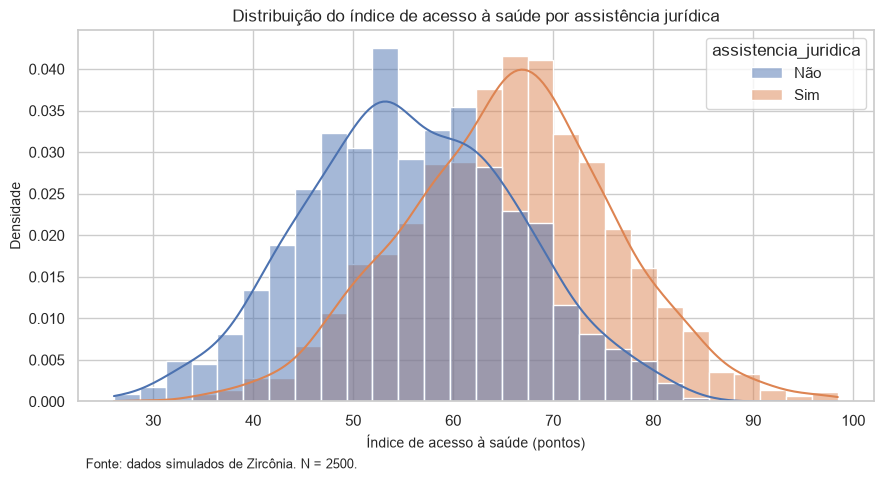

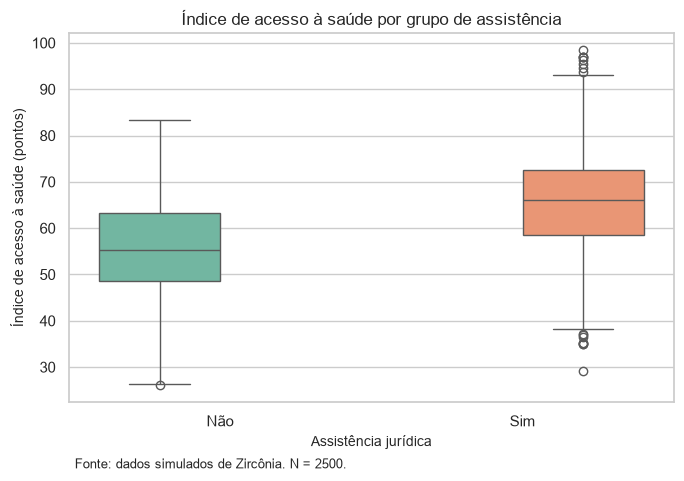

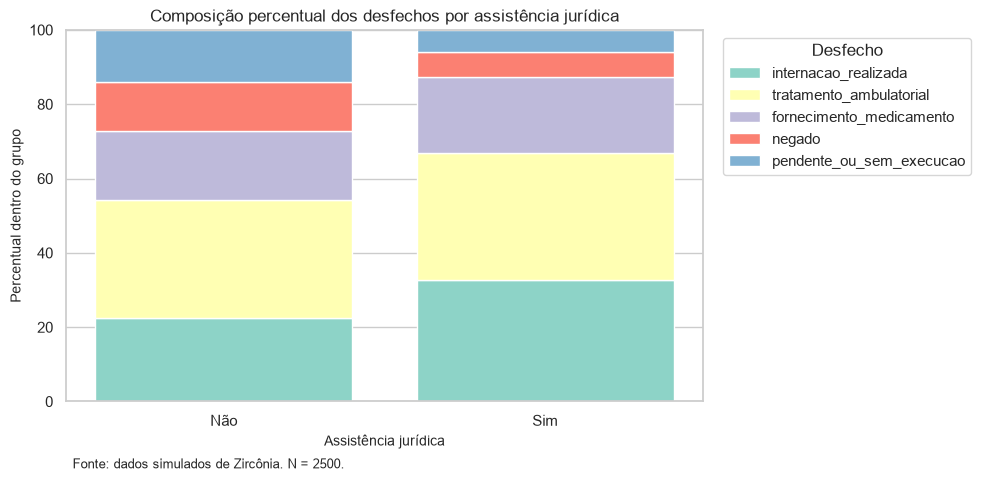

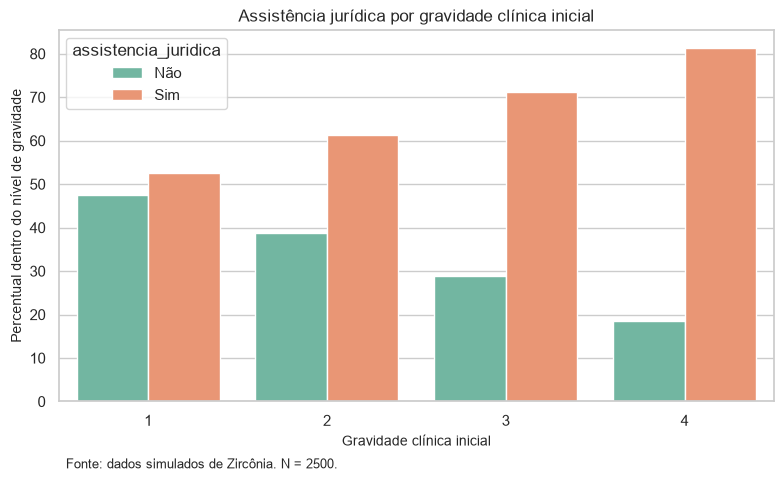

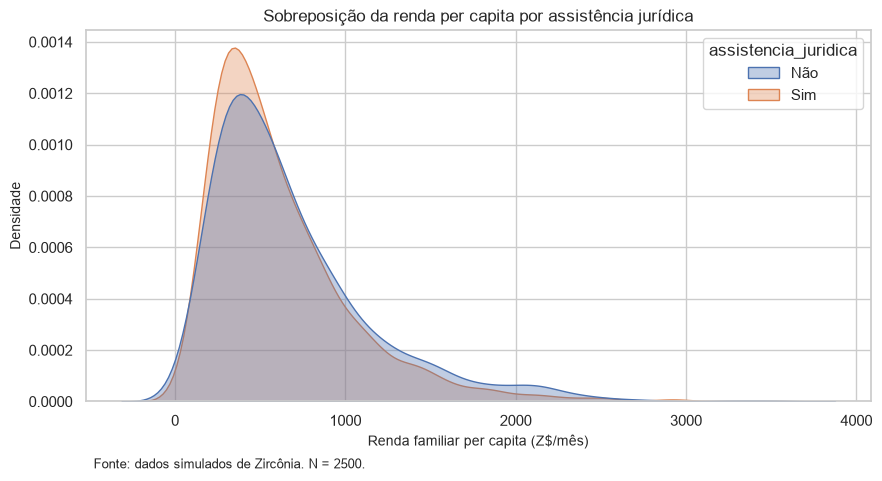

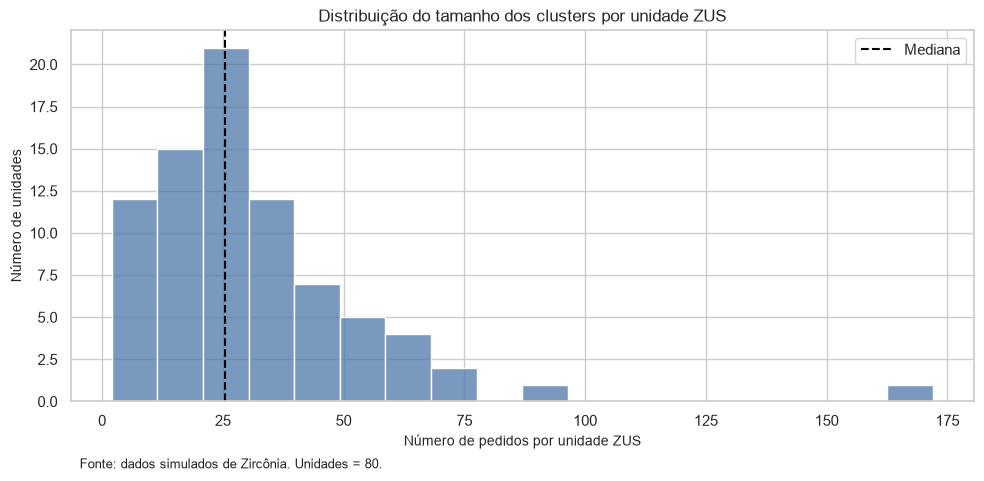

EDA concluída com tabelas e gráficos salvos em: E:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\out\cdedpp_2026_zirconia\figuras


In [5]:
# Fixar a pasta de figuras da EDA.
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Criar cópias locais para deixar claro que a EDA usa a base curada.
df_eda = dados.copy()
piloto_eda = piloto.copy()

# Validar que a EDA parte dos objetos curados, com o N esperado.
assert len(df_eda) == PARAMETROS_GERADORES["n_amostra_principal"]
assert len(piloto_eda) == tamanho_piloto
assert list(df_eda.columns) == VARIAVEIS_ANALITICAS

# Tabela de frequência absoluta e relativa dos cinco desfechos.
freq_desfecho = (
    df_eda["desfecho_pedido"]
    .value_counts(sort=False, dropna=False)
    .rename_axis("desfecho_pedido")
    .reset_index(name="n")
)
freq_desfecho["percentual"] = 100 * freq_desfecho["n"] / len(df_eda)
freq_desfecho["percentual"] = freq_desfecho["percentual"].round(2)

# Tabela 2x5 completa, preservando categorias mesmo que alguma frequência seja zero.
tabela_2x5 = pd.crosstab(
    df_eda["assistencia_juridica"],
    df_eda["desfecho_pedido"],
    dropna=False,
).reindex(index=CATEGORIAS_BINARIAS, columns=CATEGORIAS_DESFECHO, fill_value=0)
tabela_2x5_prop = tabela_2x5.div(tabela_2x5.sum(axis=1), axis=0) * 100

# Medidas resumo do índice por exposição.
resumo_indice_grupo = (
    df_eda.groupby("assistencia_juridica", observed=False)["indice_acesso_saude"]
    .agg(
        n="size",
        media="mean",
        desvio_padrao="std",
        mediana="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        minimo="min",
        maximo="max",
    )
    .round(2)
    .reset_index()
)

# Medidas resumo por unidade para visualizar heterogeneidade e tamanhos de cluster.
resumo_unidade = (
    df_eda.groupby("unidade_zus", observed=False)
    .agg(
        n=("id_pedido", "size"),
        media_indice=("indice_acesso_saude", "mean"),
        dp_indice=("indice_acesso_saude", "std"),
        prop_assistencia=("assistencia_juridica", lambda x: 100 * (x == "Sim").mean()),
        mediana_espera=("tempo_espera_dias", "median"),
    )
    .round(2)
    .reset_index()
    .sort_values(["n", "unidade_zus"], ascending=[False, True])
)

# Comparar covariáveis basais por exposição sem ainda modelar.
resumo_covariaveis = (
    df_eda.groupby("assistencia_juridica", observed=False)
    .agg(
        n=("id_pedido", "size"),
        idade_media=("idade", "mean"),
        renda_media=("renda_pc_zirc", "mean"),
        gravidade_media=("gravidade_clinica", "mean"),
        capilaridade_media=("capilaridade_defensoria", "mean"),
        pct_documentacao_completa=("completude_documental", lambda x: 100 * (x == "Sim").mean()),
        espera_mediana=("tempo_espera_dias", "median"),
    )
    .round(2)
    .reset_index()
)

# Calcular tabela de exposição por gravidade para avaliar suporte comum.
exposicao_por_gravidade = pd.crosstab(
    df_eda["gravidade_clinica"],
    df_eda["assistencia_juridica"],
    normalize="index",
    dropna=False,
).reindex(columns=CATEGORIAS_BINARIAS, fill_value=0) * 100
exposicao_por_gravidade = exposicao_por_gravidade.round(2)

# Calcular tabela de exposição por capilaridade institucional.
exposicao_por_capilaridade = pd.crosstab(
    df_eda["capilaridade_defensoria"],
    df_eda["assistencia_juridica"],
    normalize="index",
    dropna=False,
).reindex(columns=CATEGORIAS_BINARIAS, fill_value=0) * 100
exposicao_por_capilaridade = exposicao_por_capilaridade.round(2)

# Validar somas, percentuais e finitude das estatísticas.
assert freq_desfecho["n"].sum() == len(df_eda), "Frequências do desfecho não somam N."
assert set(freq_desfecho["desfecho_pedido"].astype(str)) == set(CATEGORIAS_DESFECHO)
assert tabela_2x5.to_numpy().sum() == len(df_eda), "Tabela 2x5 não soma N."
assert np.allclose(tabela_2x5_prop.sum(axis=1), 100), "Percentuais 2x5 não somam 100% por grupo."
assert set(tabela_2x5.columns) == set(CATEGORIAS_DESFECHO)
matriz_indice = resumo_indice_grupo.select_dtypes(include=[np.number]).to_numpy(dtype=float)
matriz_unidade = resumo_unidade.select_dtypes(include=[np.number]).fillna(0).to_numpy(dtype=float)
assert np.isfinite(matriz_indice).all()
assert np.isfinite(matriz_unidade).all()
assert resumo_unidade["n"].sum() == len(df_eda), "Tamanhos por unidade não somam N."
assert (resumo_unidade["n"] > 0).all(), "Há unidade exibida sem observações."
assert df_eda["indice_acesso_saude"].between(0, 100).all()
assert df_eda["assistencia_juridica"].notna().all()
assert df_eda["desfecho_pedido"].notna().all()

# Exibir tabelas exploratórias principais.
display(freq_desfecho)
display(tabela_2x5)
display(tabela_2x5_prop.round(2))
display(resumo_indice_grupo)
display(resumo_covariaveis)
display(resumo_unidade.head(12))
display(exposicao_por_gravidade)
display(exposicao_por_capilaridade)

# Gráfico 1: distribuição do índice por assistência jurídica.
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=df_eda,
    x="indice_acesso_saude",
    hue="assistencia_juridica",
    bins=28,
    stat="density",
    common_norm=False,
    kde=True,
    ax=ax,
)
ax.set_title("Distribuição do índice de acesso à saúde por assistência jurídica")
ax.set_xlabel("Índice de acesso à saúde (pontos)")
ax.set_ylabel("Densidade")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {len(df_eda)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_hist_indice_por_assistencia.png", dpi=150)
plt.show()

# Gráfico 2: boxplot do índice por assistência jurídica.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(
    data=df_eda,
    x="assistencia_juridica",
    y="indice_acesso_saude",
    hue="assistencia_juridica",
    palette="Set2",
    legend=False,
    ax=ax,
)
ax.set_title("Índice de acesso à saúde por grupo de assistência")
ax.set_xlabel("Assistência jurídica")
ax.set_ylabel("Índice de acesso à saúde (pontos)")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {len(df_eda)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_boxplot_indice_por_assistencia.png", dpi=150)
plt.show()

# Gráfico 3: composição proporcional do desfecho por assistência jurídica.
proporcoes_plot = (
    tabela_2x5_prop.reset_index()
    .melt(
        id_vars="assistencia_juridica",
        var_name="desfecho_pedido",
        value_name="percentual",
    )
)
fig, ax = plt.subplots(figsize=(10, 5))
base = np.zeros(len(CATEGORIAS_BINARIAS))
cores = sns.color_palette("Set3", n_colors=len(CATEGORIAS_DESFECHO))
for cor, categoria in zip(cores, CATEGORIAS_DESFECHO, strict=True):
    valores = proporcoes_plot.loc[
        proporcoes_plot["desfecho_pedido"] == categoria,
        "percentual",
    ].to_numpy()
    ax.bar(CATEGORIAS_BINARIAS, valores, bottom=base, label=categoria, color=cor)
    base = base + valores
ax.set_title("Composição percentual dos desfechos por assistência jurídica")
ax.set_xlabel("Assistência jurídica")
ax.set_ylabel("Percentual dentro do grupo")
ax.set_ylim(0, 100)
ax.legend(title="Desfecho", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {len(df_eda)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_barras_desfecho_por_assistencia.png", dpi=150)
plt.show()

# Gráfico 4: proporção de assistência por gravidade clínica.
gravidade_plot = exposicao_por_gravidade.reset_index().melt(
    id_vars="gravidade_clinica",
    var_name="assistencia_juridica",
    value_name="percentual",
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=gravidade_plot,
    x="gravidade_clinica",
    y="percentual",
    hue="assistencia_juridica",
    palette="Set2",
    ax=ax,
)
ax.set_title("Assistência jurídica por gravidade clínica inicial")
ax.set_xlabel("Gravidade clínica inicial")
ax.set_ylabel("Percentual dentro do nível de gravidade")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {len(df_eda)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_assistencia_por_gravidade.png", dpi=150)
plt.show()

# Gráfico 5: renda por assistência jurídica para avaliar sobreposição.
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(
    data=df_eda,
    x="renda_pc_zirc",
    hue="assistencia_juridica",
    common_norm=False,
    fill=True,
    alpha=0.35,
    ax=ax,
)
ax.set_title("Sobreposição da renda per capita por assistência jurídica")
ax.set_xlabel("Renda familiar per capita (Z$/mês)")
ax.set_ylabel("Densidade")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {len(df_eda)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_renda_por_assistencia.png", dpi=150)
plt.show()

# Gráfico 6: tamanho dos clusters por unidade ZUS.
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(resumo_unidade["n"], bins=18, ax=ax, color="#4C78A8")
ax.set_title("Distribuição do tamanho dos clusters por unidade ZUS")
ax.set_xlabel("Número de pedidos por unidade ZUS")
ax.set_ylabel("Número de unidades")
ax.axvline(resumo_unidade["n"].median(), color="black", linestyle="--", label="Mediana")
ax.legend()
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. Unidades = {resumo_unidade.shape[0]}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "eda_tamanho_clusters_unidade.png", dpi=150)
plt.show()

# Validar que os arquivos de gráficos foram produzidos.
figuras_eda = [
    "eda_hist_indice_por_assistencia.png",
    "eda_boxplot_indice_por_assistencia.png",
    "eda_barras_desfecho_por_assistencia.png",
    "eda_assistencia_por_gravidade.png",
    "eda_renda_por_assistencia.png",
    "eda_tamanho_clusters_unidade.png",
]
for figura in figuras_eda:
    caminho_figura = PASTA_FIGURAS / figura
    assert caminho_figura.is_file(), f"Figura não encontrada: {caminho_figura}"
    assert caminho_figura.stat().st_size > 0, f"Figura vazia: {caminho_figura}"

print("EDA concluída com tabelas e gráficos salvos em:", PASTA_FIGURAS)

### Interpretação exploratória

A distribuição do índice de acesso à saúde deve ser lida primeiro como
inspeção do comportamento dos dados simulados. Se o grupo com assistência
jurídica apresenta maior média ou mediana, isso é compatível com o mecanismo
gerador, mas ainda não separa efeito principal, seleção observacional e
confundimento residual.

A tabela 2x5 antecipa a análise inferencial do desfecho multinomial. O ponto
importante é preservar todas as cinco categorias, inclusive
`pendente_ou_sem_execucao`, e verificar contagens antes de escolher o teste.
A decisão entre qui-quadrado e reamostragem ficará para a seção de NHST.

Os gráficos de gravidade, renda e capilaridade ajudam a localizar
desequilíbrios basais. Se os grupos diferem nessas covariáveis, o modelo
ajustado é necessário, embora não suficiente para eliminar variáveis ocultas.
A distribuição dos tamanhos por unidade ZUS também justifica tratar a unidade
como cluster na inferência posterior.

**Registro do estudante:** quais padrões parecem substantivamente relevantes?
Há categoria rara que ameaça a estabilidade do teste? A exposição tem suporte
comum nas covariáveis principais? Alguma unidade, região ou ano domina a base?
Que diferenças brutas poderiam desaparecer ou mudar de direção após ajuste?

---

## 6. Modelagem Estatística e Diagnósticos

Esta seção estima a associação entre assistência jurídica e o índice de acesso
à saúde por regressão linear. O modelo bruto descreve a diferença média entre
grupos. O modelo ajustado inclui covariáveis medidas antes ou no contexto
inicial do pedido: gravidade clínica, renda per capita, idade, completude
documental, ano e efeitos fixos de unidade ZUS.

**Estimando primário:** coeficiente de `assistencia_binaria`, interpretado
como diferença média ajustada no `indice_acesso_saude`, em pontos, entre
pedidos com e sem assistência jurídica, condicional às covariáveis do modelo.

**Por que erros padrão agrupados?** Pedidos da mesma unidade ZUS podem
compartilhar rotinas administrativas, filas, disponibilidade local e cultura
decisória. Isso viola a independência simples dos resíduos. Por isso, o modelo
ajustado usa erros padrão agrupados por `unidade_zus`, com correção para número
finito de grupos. Efeitos fixos de unidade e erros agrupados tratam problemas
diferentes: os efeitos fixos controlam diferenças médias observáveis ou
estáveis entre unidades; os erros agrupados ajustam a incerteza quando resíduos
dentro da mesma unidade são dependentes.

**Limites.** O ajuste não elimina confundimento por variáveis omitidas, como
letramento digital ou capital social, e não transforma o estudo retrospectivo
em experimento. Além disso, o OLS resume o desfecho quantitativo; a análise do
desfecho multinomial será tratada por tabela 2x5 e teste específico na seção
seguinte.

,modelo,termo,estimativa,erro_padrao,ic95_inferior,ic95_superior,p_valor,n,r2
0,OLS bruto,assistencia_binaria,9.774,0.444,8.904,10.644,0.0,2500,0.163
1,OLS ajustado + EP cluster,assistencia_binaria,8.774,0.423,7.931,9.616,0.0,2500,0.368


,metrica,valor
0,clusters,80.0
1,menor_n_por_unidade,2.0
2,mediana_n_por_unidade,25.5
3,maior_n_por_unidade,172.0
4,n_modelo,2500.0


,variavel,vif
0,const,25.459
1,assistencia_binaria,1.045
2,gravidade_clinica,1.040
3,renda_pc_zirc,1.005
4,idade,1.002


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,193,275,160,113,122
Sim,536,557,336,110,98


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,22.36,31.87,18.54,13.09,14.14
Sim,32.74,34.03,20.53,6.72,5.99


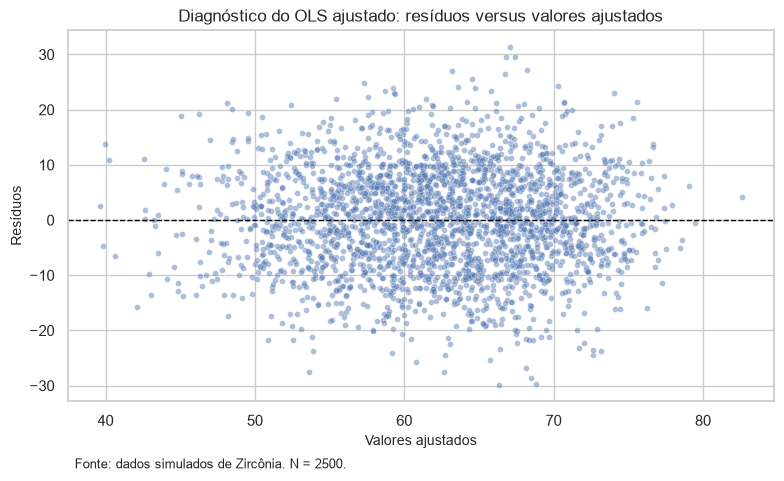

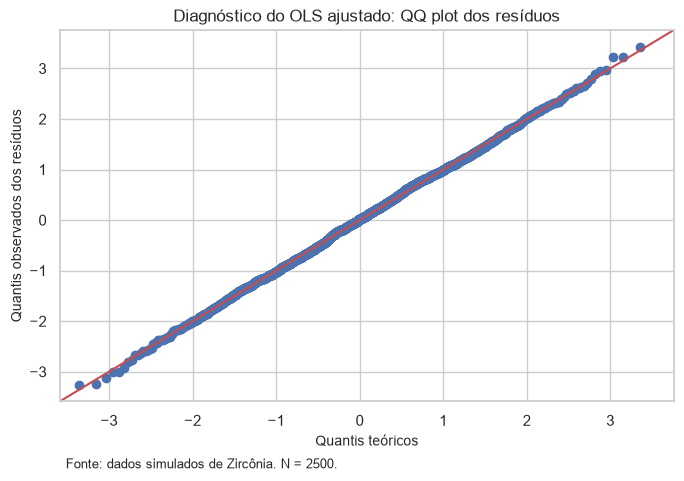

Modelagem concluída.
Coeficiente ajustado de assistência jurídica: 8.774
p-valor ajustado: 0.0
Clusters efetivos: 80


In [6]:
# Importar a API de fórmulas do statsmodels apenas na seção que a utiliza.
import statsmodels.formula.api as smf

# Criar base de modelagem a partir da base curada.
dados_modelo = dados.copy()

# Codificar a exposição principal como 0/1, preservando o rótulo original.
dados_modelo["assistencia_binaria"] = (
    dados_modelo["assistencia_juridica"].astype(str).eq("Sim").astype(int)
)

# Garantir que as variáveis categóricas entram no modelo como categorias.
dados_modelo["unidade_zus"] = dados_modelo["unidade_zus"].astype("category")
dados_modelo["ano_pedido"] = dados_modelo["ano_pedido"].astype("category")
dados_modelo["completude_documental"] = dados_modelo["completude_documental"].astype("category")

# Selecionar variáveis necessárias e remover apenas linhas incompletas do modelo.
variaveis_modelo = [
    "indice_acesso_saude",
    "assistencia_binaria",
    "gravidade_clinica",
    "renda_pc_zirc",
    "idade",
    "completude_documental",
    "ano_pedido",
    "unidade_zus",
    "desfecho_pedido",
    "assistencia_juridica",
]
dados_modelo = dados_modelo[variaveis_modelo].dropna().copy()

# Conferir que a seleção do modelo não removeu casos nesta simulação.
assert len(dados_modelo) == len(dados), "O modelo perdeu linhas por NA."
assert dados_modelo["unidade_zus"].nunique() >= 30, "Poucos clusters efetivos."
assert dados_modelo["assistencia_binaria"].nunique() == 2, "Exposição sem variação."

# Estimar modelo bruto: diferença média sem ajuste.
formula_bruta = "indice_acesso_saude ~ assistencia_binaria"
modelo_bruto = smf.ols(formula_bruta, data=dados_modelo).fit()

# Estimar modelo ajustado com efeitos fixos de unidade e ano.
formula_ajustada = (
    "indice_acesso_saude ~ assistencia_binaria"
    " + gravidade_clinica + renda_pc_zirc + idade"
    " + C(completude_documental)"
    " + C(ano_pedido)"
    " + C(unidade_zus)"
)
modelo_ajustado_ols = smf.ols(formula_ajustada, data=dados_modelo)
modelo_ajustado = modelo_ajustado_ols.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": dados_modelo["unidade_zus"],
        "use_correction": True,
    },
    use_t=True,
)

# Validar que o desenho do modelo não tem colinearidade perfeita.
matriz_desenho = modelo_ajustado_ols.exog
posto = np.linalg.matrix_rank(matriz_desenho)
n_colunas = matriz_desenho.shape[1]
assert posto == n_colunas, (
    f"Matriz de desenho sem posto completo: posto={posto}, colunas={n_colunas}."
)

# Extrair número de clusters e tamanhos de grupos usados pela inferência.
clusters_modelo = dados_modelo["unidade_zus"]
tamanhos_clusters = clusters_modelo.value_counts().sort_index()
n_clusters = int(tamanhos_clusters.shape[0])
assert n_clusters >= 30, "Inferência agrupada exige ao menos 30 clusters neste template."
assert len(clusters_modelo) == int(modelo_ajustado.nobs), "Grupos desalinhados com linhas do modelo."

# Função auxiliar para resumir coeficientes centrais.
def resumir_coeficiente(resultado, termo, nome_modelo):
    # Extrair estimativa, intervalo, erro padrão e p-valor para o termo indicado.
    intervalo = resultado.conf_int().loc[termo]
    return {
        "modelo": nome_modelo,
        "termo": termo,
        "estimativa": float(resultado.params[termo]),
        "erro_padrao": float(resultado.bse[termo]),
        "ic95_inferior": float(intervalo.iloc[0]),
        "ic95_superior": float(intervalo.iloc[1]),
        "p_valor": float(resultado.pvalues[termo]),
        "n": int(resultado.nobs),
        "r2": float(resultado.rsquared),
    }

resumo_modelos = pd.DataFrame(
    [
        resumir_coeficiente(modelo_bruto, "assistencia_binaria", "OLS bruto"),
        resumir_coeficiente(modelo_ajustado, "assistencia_binaria", "OLS ajustado + EP cluster"),
    ]
)
resumo_modelos = resumo_modelos.round(
    {
        "estimativa": 3,
        "erro_padrao": 3,
        "ic95_inferior": 3,
        "ic95_superior": 3,
        "p_valor": 4,
        "r2": 3,
    }
)

# Montar tabela de clusters para transparência sobre a dependência intraunidade.
resumo_clusters = pd.DataFrame(
    {
        "metrica": [
            "clusters",
            "menor_n_por_unidade",
            "mediana_n_por_unidade",
            "maior_n_por_unidade",
            "n_modelo",
        ],
        "valor": [
            n_clusters,
            int(tamanhos_clusters.min()),
            float(tamanhos_clusters.median()),
            int(tamanhos_clusters.max()),
            int(modelo_ajustado.nobs),
        ],
    }
)

# Diagnóstico simples de colinearidade para covariáveis substantivas sem efeitos fixos.
covariaveis_vif = dados_modelo[
    [
        "assistencia_binaria",
        "gravidade_clinica",
        "renda_pc_zirc",
        "idade",
    ]
].astype(float)
covariaveis_vif = sm.add_constant(covariaveis_vif)
from statsmodels.stats.outliers_influence import variance_inflation_factor

tabela_vif = pd.DataFrame(
    {
        "variavel": covariaveis_vif.columns,
        "vif": [
            variance_inflation_factor(covariaveis_vif.to_numpy(), indice)
            for indice in range(covariaveis_vif.shape[1])
        ],
    }
).round(3)

# Produzir tabela 2x5 completa para a próxima seção de NHST.
tabela_desfecho_2x5 = pd.crosstab(
    dados_modelo["assistencia_juridica"],
    dados_modelo["desfecho_pedido"],
    dropna=False,
).reindex(index=CATEGORIAS_BINARIAS, columns=CATEGORIAS_DESFECHO, fill_value=0)
tabela_desfecho_2x5_prop = tabela_desfecho_2x5.div(tabela_desfecho_2x5.sum(axis=1), axis=0) * 100

# Validar estimativas centrais e objetos que serão usados depois.
coef_ajustado = float(modelo_ajustado.params["assistencia_binaria"])
ic_ajustado = modelo_ajustado.conf_int().loc["assistencia_binaria"].astype(float)
p_ajustado = float(modelo_ajustado.pvalues["assistencia_binaria"])
assert np.isfinite(coef_ajustado), "Coeficiente ajustado não finito."
assert np.isfinite(ic_ajustado.to_numpy()).all(), "IC ajustado não finito."
assert np.isfinite(p_ajustado) and 0 <= p_ajustado <= 1, "p-valor ajustado inválido."
assert ic_ajustado.iloc[0] <= coef_ajustado <= ic_ajustado.iloc[1], "IC não contém estimativa."
assert 0 <= float(modelo_bruto.rsquared) <= 1, "R² bruto fora do intervalo."
assert 0 <= float(modelo_ajustado.rsquared) <= 1, "R² ajustado fora do intervalo."
assert tabela_desfecho_2x5.shape == (2, 5), "Tabela 2x5 com dimensão incorreta."
assert tabela_desfecho_2x5.to_numpy().sum() == len(dados_modelo), "Tabela 2x5 não soma N."
assert set(tabela_desfecho_2x5.columns) == set(CATEGORIAS_DESFECHO)
assert np.allclose(tabela_desfecho_2x5_prop.sum(axis=1), 100), "Percentuais 2x5 não somam 100%."

# Exibir tabelas principais do modelo.
display(resumo_modelos)
display(resumo_clusters)
display(tabela_vif)
display(tabela_desfecho_2x5)
display(tabela_desfecho_2x5_prop.round(2))

# Gráfico diagnóstico 1: resíduos versus valores ajustados.
residuos = modelo_ajustado.resid
ajustados = modelo_ajustado.fittedvalues
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=ajustados, y=residuos, s=18, alpha=0.45, ax=ax)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Diagnóstico do OLS ajustado: resíduos versus valores ajustados")
ax.set_xlabel("Valores ajustados")
ax.set_ylabel("Resíduos")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {int(modelo_ajustado.nobs)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "modelo_residuos_vs_ajustados.png", dpi=150)
plt.show()

# Gráfico diagnóstico 2: QQ plot dos resíduos.
fig = sm.qqplot(residuos, line="45", fit=True)
fig.set_size_inches(7, 5)
ax = fig.axes[0]
ax.set_title("Diagnóstico do OLS ajustado: QQ plot dos resíduos")
ax.set_xlabel("Quantis teóricos")
ax.set_ylabel("Quantis observados dos resíduos")
ax.text(
    0.01,
    -0.18,
    f"Fonte: dados simulados de Zircônia. N = {int(modelo_ajustado.nobs)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "modelo_qqplot_residuos.png", dpi=150)
plt.show()

# Validar que as figuras diagnósticas foram gravadas.
for figura in ["modelo_residuos_vs_ajustados.png", "modelo_qqplot_residuos.png"]:
    caminho_figura = PASTA_FIGURAS / figura
    assert caminho_figura.is_file(), f"Figura não encontrada: {caminho_figura}"
    assert caminho_figura.stat().st_size > 0, f"Figura vazia: {caminho_figura}"

print("Modelagem concluída.")
print("Coeficiente ajustado de assistência jurídica:", round(coef_ajustado, 3))
print("p-valor ajustado:", round(p_ajustado, 5))
print("Clusters efetivos:", n_clusters)

### Interpretação da modelagem

O modelo bruto mede a diferença média sem controle. O modelo ajustado estima a
associação condicional entre assistência jurídica e índice de acesso à saúde,
mantendo constantes as covariáveis observadas e diferenças médias entre
unidades ZUS. A comparação entre os dois coeficientes ajuda a avaliar quanto
da diferença bruta era compatível com desequilíbrio basal observado.

O p-valor e o intervalo de confiança do modelo ajustado serão formalmente
interpretados na seção de NHST. Aqui, o foco é verificar se o modelo foi
estimável, se a matriz de desenho tem posto completo, se o número de clusters
é suficiente para a aproximação usada e se os resíduos não indicam anomalias
graves. O QQ plot é diagnóstico visual; não deve ser substituído por uma
decisão automática baseada apenas em teste de normalidade.

A tabela 2x5 permanece descritiva nesta seção. Ela informa a composição do
desfecho nominal por assistência jurídica, mas o teste inferencial será
escolhido na próxima seção após verificar frequências esperadas. Mesmo quando
o teste 2x5 for significativo, ele será uma análise marginal, sem ajuste por
confundidores ou dependência intraunidade.

---

## 7. NHST e Erros de Decisão

Esta seção formaliza os testes de hipótese pré-especificados. O teste
primário usa o coeficiente ajustado de `assistencia_binaria` no OLS com erros
padrão agrupados por unidade ZUS. A regra de decisão foi fixada no início do
notebook: rejeitar $H_0$ quando `p_valor < alpha`, com `alpha = 0,05`.

**Hipótese primária bilateral:**

$H_0: \beta_{\text{assistência jurídica}} = 0$  
$H_1: \beta_{\text{assistência jurídica}} \ne 0$

O p-valor não é a probabilidade de $H_0$ ser verdadeira. Ele é a probabilidade,
sob o modelo e sob $H_0$, de obter estatística tão ou mais incompatível com
$H_0$ quanto a observada. A decisão `rejeitar` ou `não rejeitar` não substitui
a interpretação substantiva do intervalo de confiança, do tamanho da associação
e dos limites do desenho observacional.

**Hipótese secundária multinomial, marginal:**

$H_0$: a distribuição dos cinco desfechos é igual entre pedidos com e sem
assistência jurídica.  
$H_1$: ao menos uma proporção difere.

Antes de escolher o método para a tabela 2x5, o notebook calcula frequências
esperadas. Se todas forem pelo menos 5, aplica-se o qui-quadrado de Pearson.
Se alguma frequência esperada for menor que 5, aplica-se automaticamente uma
reamostragem condicional com margens fixas usando a estatística qui-quadrado.
Categorias não são colapsadas depois de observar o resultado.

,hipotese,estimativa,erro_padrao_cluster,estatistica_t,ic95_inferior,ic95_superior,p_valor,alpha,decisao,n,clusters
0,H0: beta_assistencia = 0,8.774,0.423,20.737,7.931,9.616,0.0,0.05,rejeitar H0,2500,80


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,193,275,160,113,122
Sim,536,557,336,110,98


desfecho_pedido,internacao_realizada,tratamento_ambulatorial,fornecimento_medicamento,negado,pendente_ou_sem_execucao
assistencia_juridica,,,,,
Não,251.65,287.21,171.22,76.98,75.94
Sim,477.35,544.79,324.78,146.02,144.06


,hipotese,status,metodo,chi2,gl,menor_frequencia_esperada,B_reamostragem,erro_monte_carlo,p_valor,alpha,decisao,categorias_sem_ocorrencia_total
0,H0: distribuição 2x5 igual entre grupos,estimável,qui-quadrado de Pearson,91.186,4,75.944,0,NaN,0.0,0.05,rejeitar H0,nenhuma


,erro,probabilidade_planejada,interpretação_no_estudo
0,Tipo I,0.05,Concluir associação estatisticamente significa...
1,Tipo II,0.15,Não detectar associação mínima relevante quand...
2,Poder,0.85,Probabilidade planejada de rejeitar H0 para o ...


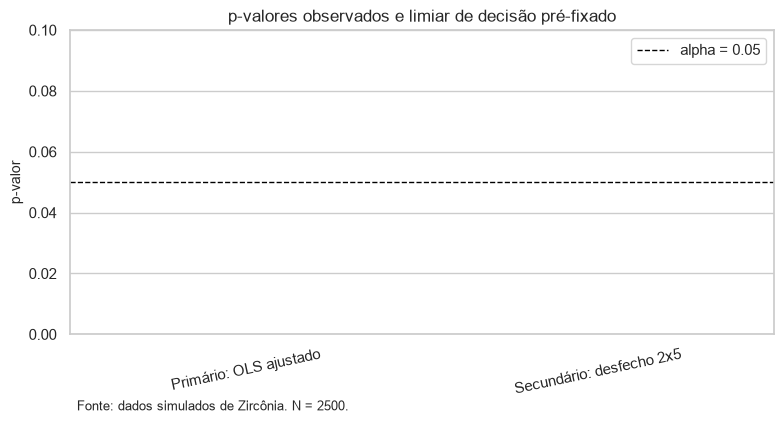

NHST concluído.
Decisão primária: rejeitar H0 | p = 0.0
Decisão secundária: rejeitar H0 | método: qui-quadrado de Pearson


In [7]:
# Extrair elementos do teste primário a partir do modelo ajustado.
termo_primario = "assistencia_binaria"
estimativa_primaria = float(modelo_ajustado.params[termo_primario])
erro_padrao_primario = float(modelo_ajustado.bse[termo_primario])
estatistica_primaria = float(modelo_ajustado.tvalues[termo_primario])
p_primario = float(modelo_ajustado.pvalues[termo_primario])
ic_primario = modelo_ajustado.conf_int().loc[termo_primario].astype(float)
decisao_primaria = "rejeitar H0" if p_primario < alpha else "não rejeitar H0"

# Montar tabela do teste primário.
resultado_primario = pd.DataFrame(
    [
        {
            "hipotese": "H0: beta_assistencia = 0",
            "estimativa": estimativa_primaria,
            "erro_padrao_cluster": erro_padrao_primario,
            "estatistica_t": estatistica_primaria,
            "ic95_inferior": float(ic_primario.iloc[0]),
            "ic95_superior": float(ic_primario.iloc[1]),
            "p_valor": p_primario,
            "alpha": alpha,
            "decisao": decisao_primaria,
            "n": int(modelo_ajustado.nobs),
            "clusters": n_clusters,
        }
    ]
)

# Validar coerência da decisão primária.
assert np.isfinite(p_primario) and 0 <= p_primario <= 1, "p primário inválido."
assert np.isfinite(estimativa_primaria), "Estimativa primária não finita."
assert np.isfinite(erro_padrao_primario) and erro_padrao_primario > 0
assert float(ic_primario.iloc[0]) <= estimativa_primaria <= float(ic_primario.iloc[1])
assert decisao_primaria == ("rejeitar H0" if p_primario < alpha else "não rejeitar H0")

# Preparar a tabela 2x5 para o teste secundário.
tabela_observada = tabela_desfecho_2x5.copy()
tabela_inferencial = tabela_observada.loc[:, tabela_observada.sum(axis=0) > 0].copy()
categorias_removidas = [
    categoria
    for categoria in tabela_observada.columns
    if tabela_observada[categoria].sum() == 0
]

# Definir função da estatística qui-quadrado de Pearson para tabelas com margens fixas.
def estatistica_chi2_tabela(tabela):
    # Calcular esperados por produto das margens e somar contribuição de Pearson.
    arr = np.asarray(tabela, dtype=float)
    total = arr.sum()
    linhas = arr.sum(axis=1, keepdims=True)
    colunas = arr.sum(axis=0, keepdims=True)
    esperadas = linhas @ colunas / total
    return float(((arr - esperadas) ** 2 / esperadas).sum())

# Selecionar o método secundário de acordo com as frequências esperadas.
status_secundario = "estimável"
metodo_secundario = None
chi2_secundario = np.nan
gl_secundario = np.nan
p_secundario = np.nan
menor_esperada = np.nan
B_reamostragem = 5000
erro_mc = np.nan
frequencias_esperadas = None

if tabela_inferencial.shape[0] < 2 or tabela_inferencial.shape[1] < 2:
    status_secundario = "teste não estimável"
    metodo_secundario = "não estimável: grupos ou categorias insuficientes"
else:
    chi2_tmp, p_tmp, gl_tmp, esperadas_tmp = stats.chi2_contingency(
        tabela_inferencial,
        correction=False,
    )
    frequencias_esperadas = pd.DataFrame(
        esperadas_tmp,
        index=tabela_inferencial.index,
        columns=tabela_inferencial.columns,
    )
    menor_esperada = float(frequencias_esperadas.to_numpy().min())
    chi2_secundario = float(chi2_tmp)
    gl_secundario = int(gl_tmp)

    if menor_esperada >= 5:
        metodo_secundario = "qui-quadrado de Pearson"
        p_secundario = float(p_tmp)
    else:
        metodo_secundario = "reamostragem condicional com margens fixas"
        rng_teste = np.random.default_rng(SEMENTE + 707)
        margens_linha = tabela_inferencial.sum(axis=1).to_numpy(dtype=int)
        margens_coluna = tabela_inferencial.sum(axis=0).to_numpy(dtype=int)
        estatisticas_simuladas = np.empty(B_reamostragem, dtype=float)

        for indice in range(B_reamostragem):
            tabela_simulada = stats.random_table.rvs(
                margens_linha,
                margens_coluna,
                random_state=rng_teste,
            )
            estatisticas_simuladas[indice] = estatistica_chi2_tabela(tabela_simulada)

        excedencias = int((estatisticas_simuladas >= chi2_secundario).sum())
        p_secundario = (1 + excedencias) / (1 + B_reamostragem)
        erro_mc = float(np.sqrt(p_secundario * (1 - p_secundario) / (B_reamostragem + 1)))

decisao_secundaria = (
    "não estimável"
    if status_secundario != "estimável"
    else ("rejeitar H0" if p_secundario < alpha else "não rejeitar H0")
)

# Montar tabela do teste secundário.
resultado_secundario = pd.DataFrame(
    [
        {
            "hipotese": "H0: distribuição 2x5 igual entre grupos",
            "status": status_secundario,
            "metodo": metodo_secundario,
            "chi2": chi2_secundario,
            "gl": gl_secundario,
            "menor_frequencia_esperada": menor_esperada,
            "B_reamostragem": B_reamostragem if "reamostragem" in str(metodo_secundario) else 0,
            "erro_monte_carlo": erro_mc,
            "p_valor": p_secundario,
            "alpha": alpha,
            "decisao": decisao_secundaria,
            "categorias_sem_ocorrencia_total": ", ".join(categorias_removidas) if categorias_removidas else "nenhuma",
        }
    ]
)

# Quadro didático dos erros de decisão no contexto do estudo.
quadro_erros_decisao = pd.DataFrame(
    [
        {
            "erro": "Tipo I",
            "probabilidade_planejada": alpha,
            "interpretação_no_estudo": (
                "Concluir associação estatisticamente significativa entre assistência jurídica "
                "e acesso à saúde quando, no modelo populacional correspondente, beta fosse zero."
            ),
        },
        {
            "erro": "Tipo II",
            "probabilidade_planejada": beta,
            "interpretação_no_estudo": (
                "Não detectar associação mínima relevante quando ela existisse no modelo populacional."
            ),
        },
        {
            "erro": "Poder",
            "probabilidade_planejada": poder_alvo,
            "interpretação_no_estudo": (
                "Probabilidade planejada de rejeitar H0 para o efeito mínimo relevante definido no protocolo."
            ),
        },
    ]
)

# Validar coerência do teste secundário.
assert tabela_observada.shape == (2, 5), "Tabela observada deve ser 2x5."
assert tabela_observada.to_numpy().sum() == int(modelo_ajustado.nobs), "Soma da tabela 2x5 incoerente."
assert set(tabela_observada.columns) == set(CATEGORIAS_DESFECHO)
if status_secundario == "estimável":
    assert np.isfinite(p_secundario) and 0 <= p_secundario <= 1, "p secundário inválido."
    assert np.isfinite(chi2_secundario) and chi2_secundario >= 0
    assert gl_secundario == (tabela_inferencial.shape[0] - 1) * (tabela_inferencial.shape[1] - 1)
    assert np.isfinite(menor_esperada) and menor_esperada > 0
    if menor_esperada >= 5:
        assert metodo_secundario == "qui-quadrado de Pearson"
    else:
        assert metodo_secundario == "reamostragem condicional com margens fixas"
        assert B_reamostragem > 0
        assert np.isfinite(erro_mc) and erro_mc >= 0
    assert decisao_secundaria == ("rejeitar H0" if p_secundario < alpha else "não rejeitar H0")
else:
    assert decisao_secundaria == "não estimável"

# Exibir resultados inferenciais.
display(resultado_primario.round(5))
display(tabela_observada)
if frequencias_esperadas is not None:
    display(frequencias_esperadas.round(2))
display(resultado_secundario.round(5))
display(quadro_erros_decisao)

# Visualizar p-valores em relação ao limiar de decisão.
grafico_pvalores = pd.DataFrame(
    {
        "teste": ["Primário: OLS ajustado", "Secundário: desfecho 2x5"],
        "p_valor": [p_primario, p_secundario if status_secundario == "estimável" else np.nan],
    }
)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=grafico_pvalores,
    x="teste",
    y="p_valor",
    hue="teste",
    palette="Set2",
    legend=False,
    ax=ax,
)
ax.axhline(alpha, color="black", linestyle="--", linewidth=1, label=f"alpha = {alpha}")
ax.set_title("p-valores observados e limiar de decisão pré-fixado")
ax.set_xlabel("")
ax.set_ylabel("p-valor")
ax.set_ylim(0, max(0.10, np.nanmax(grafico_pvalores["p_valor"].to_numpy()) * 1.25))
ax.tick_params(axis="x", rotation=12)
ax.legend()
ax.text(
    0.01,
    -0.25,
    f"Fonte: dados simulados de Zircônia. N = {int(modelo_ajustado.nobs)}.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "nhst_pvalores_alpha.png", dpi=150)
plt.show()

# Validar figura da seção.
caminho_figura = PASTA_FIGURAS / "nhst_pvalores_alpha.png"
assert caminho_figura.is_file(), f"Figura não encontrada: {caminho_figura}"
assert caminho_figura.stat().st_size > 0, f"Figura vazia: {caminho_figura}"

print("NHST concluído.")
print("Decisão primária:", decisao_primaria, "| p =", round(p_primario, 6))
print("Decisão secundária:", decisao_secundaria, "| método:", metodo_secundario)

### Interpretação dos testes

O teste primário responde à pergunta pré-especificada sobre a associação
ajustada entre assistência jurídica e índice de acesso à saúde. Se o p-valor
for menor que `alpha`, rejeita-se $H_0$ no sentido estatístico frequentista:
os dados seriam pouco compatíveis com coeficiente zero sob o modelo adotado.
Isso não prova causalidade nem elimina confundimento residual.

O teste secundário 2x5 é marginal. Ele compara distribuições dos desfechos sem
ajuste por gravidade, renda, unidade ou ano. Portanto, seu p-valor não substitui
uma análise categórica ajustada e não corrige dependência intraunidade. Sua
utilidade pedagógica é demonstrar como respeitar as frequências esperadas e
como acionar reamostragem quando o qui-quadrado assintótico for inadequado.

A decisão deve ser comunicada junto com intervalo de confiança, tamanho da
associação e limitações do desenho. Também se deve evitar a expressão “aceitar
$H_0$”: quando o p-valor não é menor que `alpha`, a conclusão correta é “não
rejeitar $H_0$”, reconhecendo a possibilidade de erro tipo II e de poder
insuficiente para efeitos menores que o planejado.

---

## 8. Tamanho Amostral e Piloto

Esta seção usa o piloto simulado com **n = 50** para demonstrar como
transformar erro tipo I, erro tipo II, desvio padrão preliminar, efeito mínimo
relevante e razão entre grupos em planejamento amostral. O piloto não serve
para “provar” a hipótese. Ele fornece insumos instáveis, mas úteis, para
dimensionamento prospectivo.

O protocolo separa três exercícios:

1. **Variável quantitativa intervalar assumida:** cálculo aproximado por teste
   t de duas amostras para `indice_acesso_saude`, usando o desvio padrão do
   piloto e a razão controle/atendido observada no piloto.
2. **Desfecho multinomial 2x5:** simulação de poder para associação entre
   assistência jurídica e cinco categorias de `desfecho_pedido`, com vetores
   de probabilidades pré-especificados sob alternativa substantiva.
3. **Calibração do OLS ajustado:** simulação de sensibilidade para o mesmo tipo
   de modelo usado na seção 6, reconhecendo efeitos fixos, covariáveis e
   inferência agrupada.

O cálculo t é apenas aproximação. Ele ignora que a regressão ajustada pode
reduzir variância residual ao controlar bons preditores, mas também pode
aumentar incerteza por colinearidade entre exposição e covariáveis, capturada
pelo $R^2$ auxiliar de `X` e pelo VIF. Também ignora dependência intraunidade,
desequilíbrio de grupos e número finito de clusters. Portanto, não deve ser
chamado de “conservador” sem demonstrar que o ganho de precisão supera essas
fontes de inflação de variância.

,parametro,valor
0,n_piloto,50.000
1,n_atendidos_piloto,33.000
2,n_controles_piloto,17.000
3,ratio_controle_por_atendido,0.515
4,s_piloto_ddof1,11.611
5,delta_minimo_relevante,5.000
6,d_cohen_piloto,0.431


,cenario,ratio_controle_por_atendido,n_atendidos,n_controles,N_total
0,ratio piloto,0.515,144,75,219
1,ratio 1.00,1.000,98,98,196
2,ratio 0.50,0.500,147,74,221
3,ratio 2.00,2.000,74,148,222


,N_grid,N_ajustado,n_atendidos,n_controles,ratio,poder_estimado,erro_mc,reps,usos_qui_quadrado,usos_reamostragem
0,120,122,80,42,0.515,0.516,0.032,250,0,250
1,180,181,119,62,0.515,0.736,0.028,250,72,178
2,240,241,159,82,0.515,0.832,0.024,250,193,57
3,300,300,198,102,0.515,0.872,0.021,250,242,8
4,360,361,238,123,0.515,0.944,0.015,250,250,0
5,420,422,278,144,0.515,0.984,0.008,250,250,0
6,480,481,317,164,0.515,0.976,0.010,250,250,0
7,540,541,357,184,0.515,0.992,0.006,250,250,0
8,600,600,396,204,0.515,0.992,0.006,250,250,0
9,660,661,436,225,0.515,1.000,0.000,250,250,0


,categoria,p_controle,p_atendido
0,internacao_realizada,0.22,0.34
1,tratamento_ambulatorial,0.32,0.33
2,fornecimento_medicamento,0.18,0.22
3,negado,0.15,0.06
4,pendente_ou_sem_execucao,0.13,0.05


,w_gof_aderencia,N_gof_uma_amostra
0,0.422,76


,N,poder_estimado,erro_mc,reps_validas
0,219,1.0,0.0,50
1,240,1.0,0.0,50
2,600,1.0,0.0,50
3,900,1.0,0.0,50


,objetivo,N_recomendado,observacao
0,Quantitativo intervalar - teste t aproximado,219,"Usa s_piloto, delta e ratio controle/atendido ..."
1,Multinomial 2x5 - associação,300,poder alvo atingido na grade
2,OLS ajustado com EP cluster - calibração,219,poder alvo atingido na grade calibrada
3,Protocolo com perdas,334,Maior N sem perdas = 300; taxa de perdas = 10%.


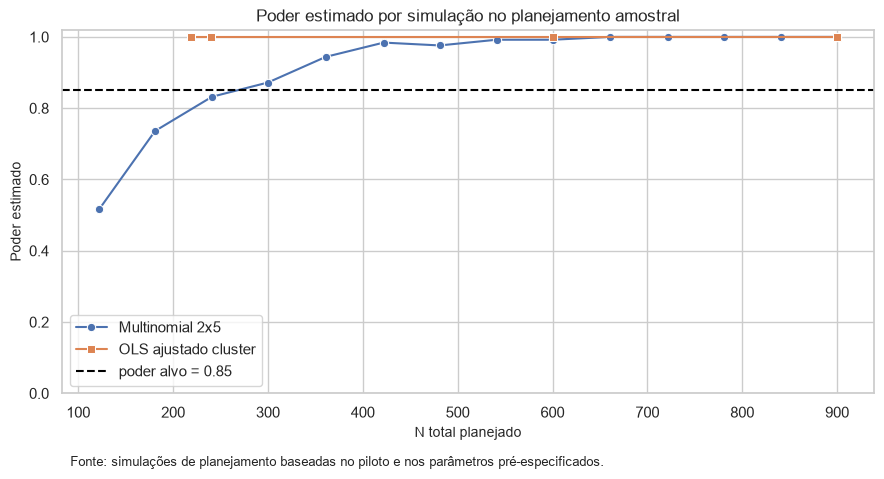

Dimensionamento amostral concluído.
N_quant: 219
N_multinomial_2x5: 300
N_OLS_calibrado: 219
N_final_com_perdas: 334


In [8]:
# Separar grupos do piloto para estimar desvio padrão e razão de alocação observada.
piloto_amostragem = piloto.copy()
n_atendidos_piloto = int((piloto_amostragem["assistencia_juridica"].astype(str) == "Sim").sum())
n_controles_piloto = int((piloto_amostragem["assistencia_juridica"].astype(str) == "Não").sum())
ratio_piloto = n_controles_piloto / n_atendidos_piloto

# Usar o desvio padrão amostral do piloto com ddof=1, como em planejamento clássico.
s_piloto = float(piloto_amostragem["indice_acesso_saude"].std(ddof=1))

# Definir efeito mínimo relevante antes de usar os testes principais.
delta_minimo_relevante = 5.0
d_cohen_piloto = delta_minimo_relevante / s_piloto

# Calcular tamanho amostral aproximado para teste t bilateral de dois grupos.
poder_t = TTestIndPower()
n_atendidos_float = poder_t.solve_power(
    effect_size=d_cohen_piloto,
    alpha=alpha,
    power=poder_alvo,
    ratio=ratio_piloto,
    alternative="two-sided",
)
n_atendidos_quant = int(np.ceil(n_atendidos_float))
n_controles_quant = int(np.ceil(ratio_piloto * n_atendidos_quant))
N_quant = n_atendidos_quant + n_controles_quant

# Avaliar sensibilidade a razões alternativas sem substituir silenciosamente o piloto por 1:1.
ratios_sensibilidade = [ratio_piloto, 1.0, 0.50, 2.00]
linhas_sensibilidade_quant = []
for ratio_cenario in ratios_sensibilidade:
    n1_cenario = poder_t.solve_power(
        effect_size=d_cohen_piloto,
        alpha=alpha,
        power=poder_alvo,
        ratio=ratio_cenario,
        alternative="two-sided",
    )
    n_atendidos_cenario = int(np.ceil(n1_cenario))
    n_controles_cenario = int(np.ceil(ratio_cenario * n_atendidos_cenario))
    linhas_sensibilidade_quant.append(
        {
            "cenario": "ratio piloto" if np.isclose(ratio_cenario, ratio_piloto) else f"ratio {ratio_cenario:.2f}",
            "ratio_controle_por_atendido": ratio_cenario,
            "n_atendidos": n_atendidos_cenario,
            "n_controles": n_controles_cenario,
            "N_total": n_atendidos_cenario + n_controles_cenario,
        }
    )
sensibilidade_quant = pd.DataFrame(linhas_sensibilidade_quant)

# Definir vetores multinomiais de cinco níveis para H1 substantiva.
p_controle_2x5 = np.array([0.22, 0.32, 0.18, 0.15, 0.13], dtype=float)
p_atendido_2x5 = np.array([0.34, 0.33, 0.22, 0.06, 0.05], dtype=float)

# Conferir probabilidades estritamente positivas e normalizadas.
assert np.all(p_controle_2x5 > 0) and np.isclose(p_controle_2x5.sum(), 1)
assert np.all(p_atendido_2x5 > 0) and np.isclose(p_atendido_2x5.sum(), 1)
assert len(p_controle_2x5) == len(CATEGORIAS_DESFECHO) == 5
assert len(p_atendido_2x5) == len(CATEGORIAS_DESFECHO) == 5

def pvalor_tabela_2x5_planejamento(tabela, seed_offset=0, b_reamostragem=399):
    # Aplicar a mesma lógica da seção 7: qui-quadrado quando esperadas >= 5,
    # reamostragem condicional quando alguma esperada for pequena.
    chi2_obs, p_chi, gl, esperadas = stats.chi2_contingency(tabela, correction=False)
    if np.asarray(esperadas).min() >= 5:
        return float(p_chi), "qui-quadrado"

    rng_local = np.random.default_rng(SEMENTE + 9000 + seed_offset)
    margens_linha = np.asarray(tabela).sum(axis=1).astype(int)
    margens_coluna = np.asarray(tabela).sum(axis=0).astype(int)
    estatisticas = np.empty(b_reamostragem, dtype=float)
    for indice in range(b_reamostragem):
        tabela_sim = stats.random_table.rvs(
            margens_linha,
            margens_coluna,
            random_state=rng_local,
        )
        total = tabela_sim.sum()
        esperada_sim = np.outer(tabela_sim.sum(axis=1), tabela_sim.sum(axis=0)) / total
        estatisticas[indice] = ((tabela_sim - esperada_sim) ** 2 / esperada_sim).sum()
    p_reamostrado = (1 + int((estatisticas >= chi2_obs).sum())) / (1 + b_reamostragem)
    return float(p_reamostrado), "reamostragem"

def estimar_poder_multinomial(N_total, ratio, reps=250):
    # Simular poder para a associação 2x5 sob alternativa pré-especificada.
    n_atendidos = int(np.ceil(N_total / (1 + ratio)))
    n_controles = int(np.ceil(ratio * n_atendidos))
    N_ajustado = n_atendidos + n_controles
    rng_mult = np.random.default_rng(SEMENTE + 3000 + int(N_total))
    rejeicoes = 0
    metodos = {"qui-quadrado": 0, "reamostragem": 0}

    for rep in range(reps):
        cont_atendidos = rng_mult.multinomial(n_atendidos, p_atendido_2x5)
        cont_controles = rng_mult.multinomial(n_controles, p_controle_2x5)
        tabela = np.vstack([cont_controles, cont_atendidos])
        p_valor, metodo = pvalor_tabela_2x5_planejamento(tabela, seed_offset=rep)
        rejeicoes += int(p_valor < alpha)
        metodos[metodo] += 1

    poder_estimado = rejeicoes / reps
    erro_mc_local = float(np.sqrt(poder_estimado * (1 - poder_estimado) / reps))
    return {
        "N_grid": N_total,
        "N_ajustado": N_ajustado,
        "n_atendidos": n_atendidos,
        "n_controles": n_controles,
        "ratio": ratio,
        "poder_estimado": poder_estimado,
        "erro_mc": erro_mc_local,
        "reps": reps,
        "usos_qui_quadrado": metodos["qui-quadrado"],
        "usos_reamostragem": metodos["reamostragem"],
    }

# Buscar o menor N em uma grade moderada para manter o notebook executável.
grade_N = list(range(120, 901, 60))
resultados_mult = pd.DataFrame(
    [estimar_poder_multinomial(N, ratio_piloto, reps=250) for N in grade_N]
)
candidatos_mult = resultados_mult.loc[
    resultados_mult["poder_estimado"] >= poder_alvo
].copy()
if candidatos_mult.empty:
    N_multinomial_2x5 = int(resultados_mult.loc[resultados_mult["poder_estimado"].idxmax(), "N_ajustado"])
    status_mult = "poder alvo não atingido na grade; ampliar busca"
else:
    N_multinomial_2x5 = int(candidatos_mult.iloc[0]["N_ajustado"])
    status_mult = "poder alvo atingido na grade"

# Cálculo complementar de aderência de uma amostra, rotulado como distinto do teste 2x5.
p0_gof = p_controle_2x5.copy()
p1_gof = p_atendido_2x5.copy()
w_gof = float(np.sqrt(np.sum((p1_gof - p0_gof) ** 2 / p0_gof)))
poder_gof = GofChisquarePower()
N_gof = int(
    np.ceil(
        poder_gof.solve_power(
            effect_size=w_gof,
            n_bins=len(CATEGORIAS_DESFECHO),
            alpha=alpha,
            power=poder_alvo,
        )
    )
)

# Calibração por simulação do OLS ajustado, com número moderado de repetições.
def calibrar_ols_cluster(N_total, reps=50):
    # Gerar bases novas e aplicar modelo semelhante ao da seção 6.
    rejeicoes = 0
    estimativas_validas = 0
    for rep in range(reps):
        simulado, _ = gerar_pedidos_simulados(
            n=N_total,
            prefixo_id=f"CAL{N_total}_{rep}",
            seed=SEMENTE + 50000 + N_total + rep,
        )
        base = simulado.copy()
        base["assistencia_binaria"] = (
            base["assistencia_juridica"].astype(str).eq("Sim").astype(int)
        )
        base["unidade_zus"] = base["unidade_zus"].astype("category")
        base["ano_pedido"] = base["ano_pedido"].astype("category")
        base["completude_documental"] = base["completude_documental"].astype("category")

        # Pular réplica se não houver dois grupos ou clusters suficientes.
        if base["assistencia_binaria"].nunique() < 2 or base["unidade_zus"].nunique() < 30:
            continue

        try:
            formula_calibracao = (
                "indice_acesso_saude ~ assistencia_binaria"
                " + gravidade_clinica + renda_pc_zirc + idade"
                " + C(completude_documental)"
                " + C(ano_pedido)"
                " + C(unidade_zus)"
            )
            ajuste_cal = smf.ols(formula_calibracao, data=base).fit(
                cov_type="cluster",
                cov_kwds={"groups": base["unidade_zus"], "use_correction": True},
                use_t=True,
            )
            p_cal = float(ajuste_cal.pvalues["assistencia_binaria"])
            if np.isfinite(p_cal):
                estimativas_validas += 1
                rejeicoes += int(p_cal < alpha)
        except Exception:
            continue

    if estimativas_validas == 0:
        return {
            "N": N_total,
            "poder_estimado": np.nan,
            "erro_mc": np.nan,
            "reps_validas": 0,
        }
    poder_estimado = rejeicoes / estimativas_validas
    erro_mc_local = float(np.sqrt(poder_estimado * (1 - poder_estimado) / estimativas_validas))
    return {
        "N": N_total,
        "poder_estimado": poder_estimado,
        "erro_mc": erro_mc_local,
        "reps_validas": estimativas_validas,
    }

grade_ols = sorted(set([max(240, N_quant // 2), N_quant, max(N_quant + 200, 600), 900]))
resultados_ols = pd.DataFrame([calibrar_ols_cluster(N, reps=50) for N in grade_ols])
candidatos_ols = resultados_ols.dropna().loc[
    resultados_ols["poder_estimado"] >= poder_alvo
]
if candidatos_ols.empty:
    N_OLS_calibrado = int(resultados_ols.dropna().sort_values("poder_estimado").iloc[-1]["N"])
    status_ols = "poder alvo não atingido na grade calibrada"
else:
    N_OLS_calibrado = int(candidatos_ols.iloc[0]["N"])
    status_ols = "poder alvo atingido na grade calibrada"

# Definir N final do protocolo, usando o maior objetivo inferencial e perdas.
taxa_perda = 0.10
N_sem_perdas = int(max(N_quant, N_multinomial_2x5, N_OLS_calibrado))
N_final = int(np.ceil(N_sem_perdas / (1 - taxa_perda)))

# Verificar contagens esperadas 2x5 para o N proposto sob as probabilidades planejadas.
n_atendidos_final = int(np.ceil(N_final / (1 + ratio_piloto)))
n_controles_final = int(np.ceil(ratio_piloto * n_atendidos_final))
esperadas_final = np.vstack(
    [
        n_controles_final * p_controle_2x5,
        n_atendidos_final * p_atendido_2x5,
    ]
)
menor_esperada_final = float(esperadas_final.min())

# Reunir síntese do dimensionamento.
resumo_amostragem = pd.DataFrame(
    [
        {
            "objetivo": "Quantitativo intervalar - teste t aproximado",
            "N_recomendado": N_quant,
            "observacao": "Usa s_piloto, delta e ratio controle/atendido do piloto.",
        },
        {
            "objetivo": "Multinomial 2x5 - associação",
            "N_recomendado": N_multinomial_2x5,
            "observacao": status_mult,
        },
        {
            "objetivo": "OLS ajustado com EP cluster - calibração",
            "N_recomendado": N_OLS_calibrado,
            "observacao": status_ols,
        },
        {
            "objetivo": "Protocolo com perdas",
            "N_recomendado": N_final,
            "observacao": f"Maior N sem perdas = {N_sem_perdas}; taxa de perdas = {taxa_perda:.0%}.",
        },
    ]
)

# Asserts exigidos pelo protocolo.
assert len(piloto_amostragem) == 50
assert s_piloto > 0
assert delta_minimo_relevante > 0
assert n_atendidos_piloto > 0 and n_controles_piloto > 0
assert ratio_piloto > 0
assert np.isclose(ratio_piloto, n_controles_piloto / n_atendidos_piloto)
assert n_controles_quant == int(np.ceil(ratio_piloto * n_atendidos_quant))
assert 0 < alpha < 1 and 0 < beta < 1 and 0 < taxa_perda < 1
assert w_gof > 0
assert N_quant > 0 and N_multinomial_2x5 > 0 and N_gof > 0 and N_OLS_calibrado > 0
assert N_final >= max(N_quant, N_multinomial_2x5, N_OLS_calibrado)
assert menor_esperada_final >= 5, "N final não garante esperadas mínimas planejadas."
assert resultados_mult["poder_estimado"].between(0, 1).all()
assert resultados_ols["poder_estimado"].dropna().between(0, 1).all()

# Exibir resultados.
parametros_piloto = pd.DataFrame(
    [
        ("n_piloto", len(piloto_amostragem)),
        ("n_atendidos_piloto", n_atendidos_piloto),
        ("n_controles_piloto", n_controles_piloto),
        ("ratio_controle_por_atendido", ratio_piloto),
        ("s_piloto_ddof1", s_piloto),
        ("delta_minimo_relevante", delta_minimo_relevante),
        ("d_cohen_piloto", d_cohen_piloto),
    ],
    columns=["parametro", "valor"],
)
display(parametros_piloto)
display(sensibilidade_quant)
display(resultados_mult.round(3))
display(pd.DataFrame({"categoria": CATEGORIAS_DESFECHO, "p_controle": p_controle_2x5, "p_atendido": p_atendido_2x5}))
display(pd.DataFrame([{"w_gof_aderencia": w_gof, "N_gof_uma_amostra": N_gof}]).round(3))
display(resultados_ols.round(3))
display(resumo_amostragem)

# Gráfico: poder estimado para multinomial e OLS calibrado.
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(
    data=resultados_mult,
    x="N_ajustado",
    y="poder_estimado",
    marker="o",
    label="Multinomial 2x5",
    ax=ax,
)
sns.lineplot(
    data=resultados_ols,
    x="N",
    y="poder_estimado",
    marker="s",
    label="OLS ajustado cluster",
    ax=ax,
)
ax.axhline(poder_alvo, color="black", linestyle="--", label=f"poder alvo = {poder_alvo:.2f}")
ax.set_title("Poder estimado por simulação no planejamento amostral")
ax.set_xlabel("N total planejado")
ax.set_ylabel("Poder estimado")
ax.set_ylim(0, 1.02)
ax.legend()
ax.text(
    0.01,
    -0.20,
    "Fonte: simulações de planejamento baseadas no piloto e nos parâmetros pré-especificados.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "amostragem_poder_simulado.png", dpi=150)
plt.show()

caminho_figura = PASTA_FIGURAS / "amostragem_poder_simulado.png"
assert caminho_figura.is_file()
assert caminho_figura.stat().st_size > 0

print("Dimensionamento amostral concluído.")
print("N_quant:", N_quant)
print("N_multinomial_2x5:", N_multinomial_2x5)
print("N_OLS_calibrado:", N_OLS_calibrado)
print("N_final_com_perdas:", N_final)

### Interpretação do dimensionamento

O cálculo quantitativo usa o desvio padrão observado no piloto e um efeito
mínimo relevante de 5 pontos no índice de acesso à saúde. Como a razão entre
controles e atendidos foi estimada em apenas 50 observações, a sensibilidade a
outras razões deve ser lida com cuidado. Não se deve substituir a razão piloto
por 1:1 sem declarar essa decisão.

O dimensionamento multinomial 2x5 usa vetores de probabilidades sob alternativa
substantiva. Esse exercício corresponde à hipótese de associação entre dois
grupos e cinco categorias; o cálculo complementar por `GofChisquarePower` é
apenas uma demonstração de aderência de uma amostra, não substitui a hipótese
2x5.

A calibração do OLS ajustado aproxima o modelo realmente usado no notebook e
explicita que o teste t simples pode ser otimista ou pessimista, conforme a
estrutura de covariáveis, colinearidade, clusters e variância residual. Em um
protocolo real, essa calibração deveria ser refinada com pressupostos vindos
de literatura, estudo piloto independente ou dados administrativos prévios,
nunca escolhida retroativamente para justificar resultados já observados.

---

## 9. Síntese e Protocolo Replicável

Esta seção organiza o que foi produzido pelo notebook em um protocolo
depositável em repositório: problema, desenho, dicionário, simulação,
curadoria, EDA, modelagem, testes de hipótese, dimensionamento amostral,
limitações e checklist de replicação.

A conclusão deve ser lida como **modelo de escrita científica**. Como os dados
são simulados, nenhuma frase deve afirmar que uma política real da Zircônia
funcionou. O resultado é didático: mostra como um estudo observacional
retrospectivo poderia ser planejado, auditado, analisado e documentado.

**Estrutura recomendada para o relatório do estudante:**

| Parte | Conteúdo mínimo |
|---|---|
| Problema | Delimitação T.E.M.P., população-alvo, população acessível e unidade de análise |
| Teoria | Mecanismo esperado, hipótese rival e variáveis ocultas plausíveis |
| Variáveis | Dicionário, escala, unidade de medida, tipo Python, papel e fonte |
| Dados | Sistema de referência, critérios de inclusão/exclusão, curadoria e perdas |
| EDA | Frequências, medidas resumo, gráficos e sinais de desequilíbrio basal |
| Modelagem | Estimando, covariáveis, clusters, diagnóstico e tamanho da associação |
| NHST | $H_0$, $H_1$, alpha, p-valor, IC, erro tipo I, erro tipo II e decisão |
| Amostragem | Piloto, desvio padrão, razão entre grupos, poder, perdas e sensibilidade |
| Limitações | Validade interna, externa, mensuração, seleção e confundimento residual |
| Repositório | Notebook, dados simulados, dicionário, plano, ambiente e scripts |

In [9]:
# Reunir elementos centrais calculados nas seções anteriores.
resumo_reprodutivel = pd.DataFrame(
    [
        {"campo": "notebook", "valor": "CDEaDPP_2026_Trabalho_Final_Zirconia.ipynb"},
        {"campo": "plano", "valor": "PLANO_CDEaDPP_2026_Trabalho_Final_Zirconia.md"},
        {"campo": "caso", "valor": "Zircônia - acesso à saúde e acesso à justiça"},
        {"campo": "desenho", "valor": "estudo observacional retrospectivo com dados simulados"},
        {"campo": "unidade_analise", "valor": "pedido individual de acesso à saúde"},
        {"campo": "semente", "valor": SEMENTE},
        {"campo": "alpha", "valor": alpha},
        {"campo": "beta", "valor": beta},
        {"campo": "poder_alvo", "valor": poder_alvo},
        {"campo": "n_piloto", "valor": len(piloto)},
        {"campo": "n_amostra_principal", "valor": len(dados)},
        {"campo": "n_modelo", "valor": int(modelo_ajustado.nobs)},
        {"campo": "clusters_unidade_zus", "valor": n_clusters},
        {"campo": "efeito_gerador_indice", "valor": PARAMETROS_GERADORES["efeito_assistencia_indice"]},
        {"campo": "estimativa_ols_ajustada", "valor": estimativa_primaria},
        {"campo": "ic95_inferior_ols", "valor": float(ic_primario.iloc[0])},
        {"campo": "ic95_superior_ols", "valor": float(ic_primario.iloc[1])},
        {"campo": "p_valor_ols_ajustado", "valor": p_primario},
        {"campo": "decisao_primaria", "valor": decisao_primaria},
        {"campo": "metodo_teste_2x5", "valor": metodo_secundario},
        {"campo": "p_valor_2x5", "valor": p_secundario},
        {"campo": "decisao_secundaria", "valor": decisao_secundaria},
        {"campo": "s_piloto", "valor": s_piloto},
        {"campo": "ratio_piloto_controle_por_atendido", "valor": ratio_piloto},
        {"campo": "N_quant", "valor": N_quant},
        {"campo": "N_multinomial_2x5", "valor": N_multinomial_2x5},
        {"campo": "N_OLS_calibrado", "valor": N_OLS_calibrado},
        {"campo": "N_final_com_perdas", "valor": N_final},
        {"campo": "csv_principal", "valor": str(PASTA_SAIDA / "zirconia_pedidos_simulados.csv")},
        {"campo": "csv_piloto", "valor": str(PASTA_SAIDA / "zirconia_piloto_simulado.csv")},
        {"campo": "pasta_figuras", "valor": str(PASTA_FIGURAS)},
    ]
)

# Registrar versões novamente no encerramento para facilitar auditoria externa.
versoes_finais = pd.DataFrame(
    {
        "pacote": list(versoes.keys()),
        "versao": list(versoes.values()),
    }
)

# Montar checklist objetivo de replicabilidade.
checklist_replicacao = pd.DataFrame(
    [
        ("Plano metodológico existe", (RAIZ_PROJETO / "PLANO_CDEaDPP_2026_Trabalho_Final_Zirconia.md").is_file()),
        ("Notebook gerado existe", (RAIZ_PROJETO / "CDEaDPP_2026_Trabalho_Final_Zirconia.ipynb").is_file()),
        ("CSV principal existe", (PASTA_SAIDA / "zirconia_pedidos_simulados.csv").is_file()),
        ("CSV piloto existe", (PASTA_SAIDA / "zirconia_piloto_simulado.csv").is_file()),
        ("Dicionário cobre variáveis analíticas", set(VARIAVEIS_ANALITICAS).issubset(set(dicionario["nome"]))),
        ("Latente excluída da base analítica", "letramento_digital_latente" not in dados.columns),
        ("Piloto distinto da amostra principal", set(piloto["id_pedido"]).isdisjoint(set(dados["id_pedido"]))),
        ("Amostra principal sem NA", int(dados.isna().sum().sum()) == 0),
        ("Tabela 2x5 completa", tabela_desfecho_2x5.shape == (2, 5)),
        ("Modelo com ao menos 30 clusters", n_clusters >= 30),
        ("N final cobre objetivos inferenciais", N_final >= max(N_quant, N_multinomial_2x5, N_OLS_calibrado)),
    ],
    columns=["item", "ok"],
)

# Preparar texto sintético parametrizado por resultados efetivamente calculados.
conclusao_parametrizada = pd.DataFrame(
    [
        {
            "elemento": "resultado_primario",
            "texto": (
                f"No conjunto simulado, a associação ajustada entre assistência jurídica "
                f"e índice de acesso à saúde foi de {estimativa_primaria:.2f} pontos "
                f"(IC95% {float(ic_primario.iloc[0]):.2f}; {float(ic_primario.iloc[1]):.2f}; "
                f"p={p_primario:.3g}), com decisão: {decisao_primaria}."
            ),
        },
        {
            "elemento": "resultado_secundario",
            "texto": (
                f"Para o desfecho multinomial 2x5, o método aplicado foi "
                f"{metodo_secundario}, com p={p_secundario:.3g} e decisão: "
                f"{decisao_secundaria}."
            ),
        },
        {
            "elemento": "amostragem",
            "texto": (
                f"O dimensionamento indicou N final de {N_final} pedidos após "
                f"correção por perdas, considerando N_quant={N_quant}, "
                f"N_multinomial_2x5={N_multinomial_2x5} e "
                f"N_OLS_calibrado={N_OLS_calibrado}."
            ),
        },
    ]
)

# Asserts finais de coerência e rastreabilidade.
campos_obrigatorios = {
    "notebook",
    "plano",
    "semente",
    "alpha",
    "beta",
    "poder_alvo",
    "n_piloto",
    "n_amostra_principal",
    "estimativa_ols_ajustada",
    "ic95_inferior_ols",
    "ic95_superior_ols",
    "p_valor_ols_ajustado",
    "N_final_com_perdas",
}
assert campos_obrigatorios.issubset(set(resumo_reprodutivel["campo"]))
assert int(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "n_piloto", "valor"].iloc[0]) == len(piloto)
assert int(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "n_amostra_principal", "valor"].iloc[0]) == len(dados)
assert np.isclose(
    float(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "estimativa_ols_ajustada", "valor"].iloc[0]),
    estimativa_primaria,
)
assert np.isclose(
    float(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "ic95_inferior_ols", "valor"].iloc[0]),
    float(ic_primario.iloc[0]),
)
assert np.isclose(
    float(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "ic95_superior_ols", "valor"].iloc[0]),
    float(ic_primario.iloc[1]),
)
assert np.isclose(
    float(resumo_reprodutivel.loc[resumo_reprodutivel["campo"] == "p_valor_ols_ajustado", "valor"].iloc[0]),
    p_primario,
)
assert checklist_replicacao["ok"].all(), "Algum item do checklist final falhou."
assert "estcaso_lide_pred" not in str(PASTA_SAIDA).lower()
assert "rafael" not in str(PASTA_SAIDA).lower()
assert not any(col.startswith("prob_") for col in dados.columns)

# Exibir síntese final.
display(resumo_reprodutivel)
display(versoes_finais)
display(checklist_replicacao)
display(conclusao_parametrizada)

print("Síntese final concluída.")
print(f"Notebook completo: {RAIZ_PROJETO / 'CDEaDPP_2026_Trabalho_Final_Zirconia.ipynb'}")
print(f"N final recomendado no protocolo didático: {N_final}")

,campo,valor
0,notebook,CDEaDPP_2026_Trabalho_Final_Zirconia.ipynb
1,plano,PLANO_CDEaDPP_2026_Trabalho_Final_Zirconia.md
2,caso,Zircônia - acesso à saúde e acesso à justiça
3,desenho,estudo observacional retrospectivo com dados s...
4,unidade_analise,pedido individual de acesso à saúde
5,semente,2026
6,alpha,0.05
7,beta,0.15
8,poder_alvo,0.85
9,n_piloto,50


,pacote,versao
0,numpy,2.5.2
1,pandas,3.0.5
2,matplotlib,3.11.1
3,seaborn,0.13.2
4,scipy,1.18.0
5,statsmodels,0.14.6


,item,ok
0,Plano metodológico existe,True
1,Notebook gerado existe,True
2,CSV principal existe,True
3,CSV piloto existe,True
4,Dicionário cobre variáveis analíticas,True
5,Latente excluída da base analítica,True
6,Piloto distinto da amostra principal,True
7,Amostra principal sem NA,True
8,Tabela 2x5 completa,True
9,Modelo com ao menos 30 clusters,True


,elemento,texto
0,resultado_primario,"No conjunto simulado, a associação ajustada en..."
1,resultado_secundario,"Para o desfecho multinomial 2x5, o método apli..."
2,amostragem,O dimensionamento indicou N final de 334 pedid...


Síntese final concluída.
Notebook completo: E:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\CDEaDPP_2026_Trabalho_Final_Zirconia.ipynb
N final recomendado no protocolo didático: 334


### Conclusão acadêmica do template

No caso simulado de Zircônia, o notebook ilustra um protocolo completo para
investigar a associação entre assistência jurídica institucional e acesso
efetivo à saúde em pedidos de pessoas de baixa renda. A simulação criou um
efeito gerador positivo, covariáveis observadas, heterogeneidade territorial e
uma variável latente omitida, de modo a aproximar o exercício das dificuldades
de um estudo observacional retrospectivo.

Os resultados estimados no notebook devem ser interpretados como demonstração
metodológica. Um coeficiente estatisticamente significativo no OLS ajustado
indica incompatibilidade dos dados simulados com coeficiente zero sob o modelo
adotado, mas não demonstra, sozinho, causalidade. A validade interna continua
ameaçada por seleção observacional, confundimento residual, erro de medida e
eventual especificação incompleta do modelo. A validade externa depende da
cobertura do sistema de referência, da capilaridade institucional e da
comparabilidade entre a população simulada e a população real que o estudante
venha a estudar.

O desfecho multinomial 2x5 oferece uma análise secundária e marginal. Mesmo
quando seu teste rejeita $H_0$, ele não ajusta por gravidade, renda, unidade,
ano ou dependência intraunidade. Ele deve ser apresentado como evidência
complementar de associação entre distribuição de desfechos e assistência
jurídica, não como substituto de modelagem categórica ajustada.

O dimensionamento amostral mostra que o piloto n=50 é útil para obter uma
primeira estimativa de desvio padrão e razão entre grupos, mas essas estimativas
são instáveis. Por isso, o protocolo recomenda análise de sensibilidade,
explicitação do efeito mínimo relevante e calibração por simulação quando o
modelo final inclui covariáveis, efeitos fixos e erros agrupados.

**Checklist para depósito em repositório antes da coleta real:**

- Problema de pesquisa delimitado em tempo, espaço, matéria e população.
- Dicionário de dados com nome, significado, escala, unidade, tipo Python,
  papel analítico, fonte e exemplos.
- Critérios de inclusão, exclusão, tratamento de NA e duplicatas.
- Plano de simulação ou piloto independente documentado.
- Hipóteses primária e secundária com alpha, beta e poder pré-definidos.
- Scripts/notebook executáveis do início ao fim.
- Ambiente computacional e versões de pacotes registradas.
- Estratégia para variáveis ocultas, confundimento e validade externa.
- Plano de análise de resíduos, clusters, categorias esparsas e sensibilidade.

Ao substituir os dados simulados por dados reais, o estudante deve revisar cada
pressuposto, declarar perdas e limitações, e evitar qualquer conclusão que vá
além do desenho efetivamente sustentado pelos dados.